#### Notebook 03 — Residence Classification and Target-Area Presence Estimation

Notebook 03 builds directly from Notebook 02 and takes the project from estimating a subscriber's likely home location to understanding their residential behaviour and geographic presence.

The central question is:

Given a subscriber's inferred home location and observed mobile network activity, can we determine whether they are likely to be a stable resident, have multiple recurring residential locations, exhibit short-term presence, or have insufficient evidence? Can we also estimate whether they are likely to reside in or have been observed in a particular target geographic area?

This notebook answers the question: 
- Is their residential pattern stable?
- Do they have recurring nighttime activity in multiple locations?
- Is there enough evidence to classify their residence?
- Does their inferred home fall inside a particular intervention area?
- Are they observed in an intervention area even if their inferred home is elsewhere?

#### Part 1 — Setup and configuration

In [588]:
# 1: Import libraries

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

sns.set_theme(style="whitegrid")

In [589]:
# 2: Configure project paths

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_PATH = PROJECT_ROOT / "data" / "raw"

PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"

NOTEBOOK02_OUTPUT = PROCESSED_PATH / "notebook_02"

NOTEBOOK03_OUTPUT = PROCESSED_PATH / "notebook_03"

REPORT_PATH = PROJECT_ROOT / "reports"

EXTERNAL_PATH = PROJECT_ROOT / "data" / "external"

NOTEBOOK03_OUTPUT.mkdir(parents=True, exist_ok=True)
REPORT_PATH.mkdir(parents=True, exist_ok=True)
EXTERNAL_PATH.mkdir(parents=True, exist_ok=True)


DATA_FILE = (
    RAW_PATH
    / "MPD_sample_synthetic_ken_3000subs_full.csv"
)

HOME_ESTIMATES_FILE = (
    NOTEBOOK02_OUTPUT
    / "home_location_estimates.csv"
)

SUBSCRIBER_CLASSIFICATION_FILE = (
    NOTEBOOK02_OUTPUT
    / "subscriber_classification.csv"
)

CANDIDATE_FEATURES_FILE = (
    NOTEBOOK02_OUTPUT
    / "nighttime_cell_candidates.csv"
)

CELL_VALIDATION_FILE = (
    NOTEBOOK02_OUTPUT
    / "cell_coordinate_validation.csv"
)


# Residence classification parameters

NIGHT_START_HOUR = 20
NIGHT_END_HOUR = 6

HOME_RADIUS_KM = 1.0

MIN_HOME_NIGHTS = 3

MIN_DISTINCT_NIGHTS = 3

STABLE_MIN_HOME_NIGHTS = 10
STABLE_MIN_ACTIVE_WEEKS = 3
STABLE_MIN_HOME_PRESENCE_RATIO = 0.50

TEMPORARY_MAX_SPAN_DAYS = 7
TEMPORARY_MAX_ACTIVE_WEEKS = 1

# Alternative residential location detection
ALTERNATIVE_LOCATION_EPS_KM = 1.0
ALTERNATIVE_LOCATION_MIN_SAMPLES = 2

MIN_ALTERNATIVE_LOCATION_NIGHTS = 3
MIN_ALTERNATIVE_LOCATION_DISTANCE_KM = 5.0

# Home location fallback
USE_METHOD1_FALLBACK = True

# Geographic target areas
TARGET_AREAS_FILE = (
    EXTERNAL_PATH / "target_areas.geojson"
)

EARTH_RADIUS_KM = 6371.0088


print("Project root:", PROJECT_ROOT)
print("Notebook 02 outputs:", NOTEBOOK02_OUTPUT)
print("Notebook 03 outputs:", NOTEBOOK03_OUTPUT)
print("Target areas:", TARGET_AREAS_FILE)

Project root: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference
Notebook 02 outputs: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_02
Notebook 03 outputs: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_03
Target areas: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/external/target_areas.geojson


In [590]:
# 3: Validate input files

required_files = [
    DATA_FILE,
    HOME_ESTIMATES_FILE,
    SUBSCRIBER_CLASSIFICATION_FILE,
    CANDIDATE_FEATURES_FILE,
    CELL_VALIDATION_FILE
]

missing_files = [
    file for file in required_files
    if not file.exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following required files are missing:\n"
        + "\n".join(str(file) for file in missing_files)
    )

print("All required Notebook 02 input files are available.")

All required Notebook 02 input files are available.


#### Part 2 — Load Notebook 02 outputs

In [591]:
# 4: Load the full dataset and Notebook 02 outputs

df_full = pd.read_csv(
    DATA_FILE,
    dtype={
        "msisdn": "string",
        "cell_id": "string",
        "latitude": "float64",
        "longitude": "float64",
        "data_type": "category",
        "service": "category",
        "location_target": "category",
        "location_place": "category",
        "profile": "category",
        "record_profile": "category",
        "movement_profile": "category"
    },
    low_memory=False
)

home_estimates = pd.read_csv(
    HOME_ESTIMATES_FILE,
    dtype={"msisdn": "string"}
)

subscriber_flags = pd.read_csv(
    SUBSCRIBER_CLASSIFICATION_FILE,
    dtype={"msisdn": "string"}
)

candidate_features = pd.read_csv(
    CANDIDATE_FEATURES_FILE,
    dtype={
        "msisdn": "string",
        "cell_id": "string"
    }
)

cell_geo_profile = pd.read_csv(
    CELL_VALIDATION_FILE,
    dtype={"cell_id": "string"}
)


print("Full dataset:", df_full.shape)
print("Home estimates:", home_estimates.shape)
print("Subscriber classifications:", subscriber_flags.shape)
print("Nighttime candidates:", candidate_features.shape)
print("Cell validation:", cell_geo_profile.shape)

Full dataset: (1072608, 16)
Home estimates: (2813, 32)
Subscriber classifications: (3000, 11)
Nighttime candidates: (24097, 12)
Cell validation: (35928, 12)


In [592]:
# 5: Convert data types

df_full["datetime"] = pd.to_datetime(
    df_full["datetime"],
    errors="coerce"
)

for col in ["latitude", "longitude", "movement_dist", "movement_speed"]:
    df_full[col] = pd.to_numeric(
        df_full[col],
        errors="coerce"
    )

# Convert synthetic Boolean labels safely.
def convert_to_boolean(series):
    mapped = (
        series.astype("string")
        .str.strip()
        .str.lower()
        .map({
            "1": True,
            "0": False,
            "true": True,
            "false": False,
            "yes": True,
            "no": False
        })
    )

    return mapped.astype("boolean")


df_full["tourist"] = convert_to_boolean(df_full["tourist"])
df_full["is_robot"] = convert_to_boolean(df_full["is_robot"])

coordinate_columns = [
    "method1_home_latitude",
    "method1_home_longitude",
    "method4_home_latitude",
    "method4_home_longitude"
]

for col in coordinate_columns:
    home_estimates[col] = pd.to_numeric(
        home_estimates[col],
        errors="coerce"
    )

for col in [
    "median_latitude",
    "median_longitude",
    "nighttime_events",
    "distinct_nights",
    "night_presence_ratio",
    "night_event_share"
]:
    if col in candidate_features.columns:
        candidate_features[col] = pd.to_numeric(
            candidate_features[col],
            errors="coerce"
        )

categorical_columns = [
    "data_type",
    "service",
    "location_target",
    "location_place",
    "profile",
    "record_profile",
    "movement_profile"
]

for col in categorical_columns:
    if col in df_full.columns:
        df_full[col] = df_full[col].astype("category")

print("Data type conversion completed.")

print(df_full.dtypes)

Data type conversion completed.
msisdn                      string
datetime            datetime64[us]
cell_id                     string
latitude                   float64
longitude                  float64
data_type                 category
service                   category
location_target           category
location_place            category
movement_dist              float64
movement_speed             float64
is_robot                   boolean
profile                   category
tourist                    boolean
record_profile            category
movement_profile          category
dtype: object


In [593]:
# 6: Validate Notebook 02 outputs

print("Ordinary subscribers:", subscriber_flags.loc[
    subscriber_flags["subscriber_type"] == "ordinary",
    "msisdn"
].nunique())

print("Subscribers in home estimates:", home_estimates["msisdn"].nunique())

print("Duplicate subscriber estimates:", home_estimates["msisdn"].duplicated().sum())

print("Missing DBSCAN coordinates:", home_estimates["method4_home_latitude"].isna().sum())

print("Missing Method 1 coordinates:", home_estimates["method1_home_latitude"].isna().sum())

assert home_estimates["msisdn"].is_unique

assert set(home_estimates["msisdn"]).issubset(
    set(
        subscriber_flags.loc[
            subscriber_flags["subscriber_type"] == "ordinary",
            "msisdn"
        ]
    )
)

print("Notebook 02 output validation passed.")

Ordinary subscribers: 2813
Subscribers in home estimates: 2813
Duplicate subscriber estimates: 0
Missing DBSCAN coordinates: 740
Missing Method 1 coordinates: 55
Notebook 02 output validation passed.


#### Part 3 — Select residential coordinates

Only one home-location estimate per subscriber is needed.

The preferred hierarchy is:
1. DBSCAN estimate, where available.
2. Method 1 estimate, where DBSCAN is unavailable and the subscriber meets the minimum observation requirement, if fallback is enabled.
3. No estimate, where neither method provides sufficient evidence.

In [594]:
# 7: Construct the selected home-location dataset

residence_estimates = home_estimates.copy()

residence_estimates["selected_home_latitude"] = np.nan
residence_estimates["selected_home_longitude"] = np.nan

residence_estimates["selected_home_method"] = "no_estimate"


# Use DBSCAN wherever coordinates are available.
dbscan_mask = (
    residence_estimates["method4_home_latitude"].notna()
    & residence_estimates["method4_home_longitude"].notna()
)

residence_estimates.loc[
    dbscan_mask,
    "selected_home_latitude"
] = residence_estimates.loc[
    dbscan_mask,
    "method4_home_latitude"
]

residence_estimates.loc[
    dbscan_mask,
    "selected_home_longitude"
] = residence_estimates.loc[
    dbscan_mask,
    "method4_home_longitude"
]

residence_estimates.loc[
    dbscan_mask,
    "selected_home_method"
] = "DBSCAN"


# Optional Method 1 fallback.
if USE_METHOD1_FALLBACK:

    fallback_mask = (
        ~dbscan_mask
        & residence_estimates["method1_home_latitude"].notna()
        & residence_estimates["method1_home_longitude"].notna()
        & (
            residence_estimates["valid_distinct_nights"]
            >= MIN_DISTINCT_NIGHTS
        )
    )

    residence_estimates.loc[
        fallback_mask,
        "selected_home_latitude"
    ] = residence_estimates.loc[
        fallback_mask,
        "method1_home_latitude"
    ]

    residence_estimates.loc[
        fallback_mask,
        "selected_home_longitude"
    ] = residence_estimates.loc[
        fallback_mask,
        "method1_home_longitude"
    ]

    residence_estimates.loc[
        fallback_mask,
        "selected_home_method"
    ] = "Method 1 fallback"


residence_estimates["has_home_estimate"] = (
    residence_estimates["selected_home_latitude"].notna()
    & residence_estimates["selected_home_longitude"].notna()
)

display(
    residence_estimates["selected_home_method"]
    .value_counts()
    .to_frame("subscriber_count")
)


,subscriber_count
selected_home_method,
DBSCAN,2073
Method 1 fallback,496
no_estimate,244


,home_estimation_method,subscriber_count,percentage
0,DBSCAN,2073,73.6936
1,Method 1 fallback,496,17.6324
2,no_estimate,244,8.6740


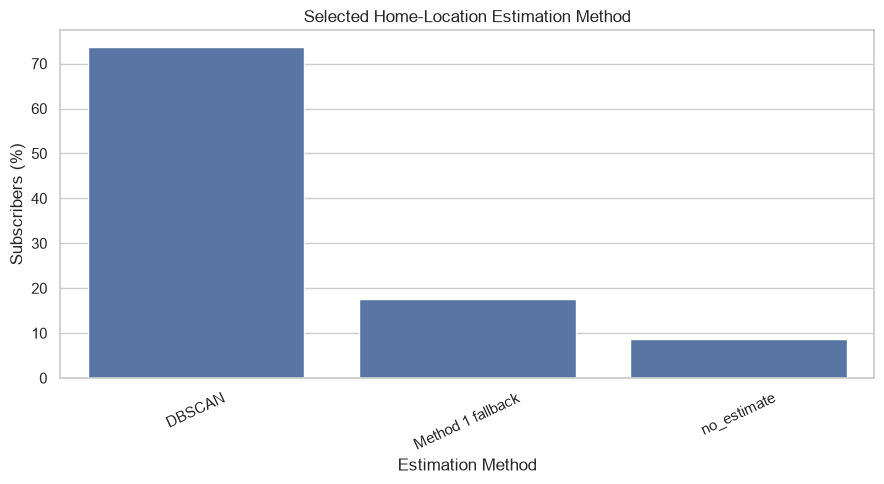

In [595]:
# 8: Summarise selected home-location methods

home_method_summary = (
    residence_estimates["selected_home_method"]
    .value_counts()
    .rename_axis("home_estimation_method")
    .reset_index(name="subscriber_count")
)

home_method_summary["percentage"] = (
    home_method_summary["subscriber_count"]
    / home_method_summary["subscriber_count"].sum()
    * 100
)

display(home_method_summary)


plt.figure(figsize=(9, 5))

sns.barplot(
    data=home_method_summary,
    x="home_estimation_method",
    y="percentage"
)

plt.title("Selected Home-Location Estimation Method")
plt.xlabel("Estimation Method")
plt.ylabel("Subscribers (%)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [596]:
# 9: Inspect the selected home estimates

display(
    residence_estimates[
        [
            "msisdn",
            "selected_home_latitude",
            "selected_home_longitude",
            "selected_home_method",
            "confidence",
            "valid_distinct_nights",
            "valid_nighttime_events",
            "has_home_estimate"
        ]
    ].head(20)
)

,msisdn,selected_home_latitude,selected_home_longitude,selected_home_method,confidence,valid_distinct_nights,valid_nighttime_events,has_home_estimate
0,subscribers_00000,-1.2556,36.7837,Method 1 fallback,high,3,3,True
1,subscribers_00001,-1.3088,36.8662,DBSCAN,low,6,6,True
2,subscribers_00002,-1.2855,36.8307,DBSCAN,medium,16,28,True
3,subscribers_00003,-1.2735,36.8369,DBSCAN,high,26,56,True
4,subscribers_00004,-1.3870,36.7660,DBSCAN,low,4,7,True
5,subscribers_00005,-1.3296,36.7565,DBSCAN,low,12,24,True
6,subscribers_00006,NaN,NaN,no_estimate,insufficient_evidence,2,2,False
7,subscribers_00007,-1.1916,36.8876,DBSCAN,high,26,89,True
8,subscribers_00008,-1.2482,36.6640,DBSCAN,high,15,22,True
9,subscribers_00009,NaN,NaN,no_estimate,insufficient_evidence,2,2,False


### Interpretation and Summary

The table shows the final residential home-location estimates for individual subscribers, combining DBSCAN with a fallback method.

- **DBSCAN is the primary method:** Most subscribers shown have home coordinates estimated using DBSCAN.
- **Fallback mechanism:** Some subscribers, such as `subscribers_00000` and `subscribers_00013`, receive estimates through Method 1 fallback when DBSCAN does not provide an estimate.
- **Confidence levels:** Estimates are classified as high or low confidence, with some subscribers having medium confidence.
- **Insufficient evidence:** Subscribers such as `subscribers_00006` and `subscribers_00009` have no estimated coordinates because their nighttime activity is insufficient.
- **Observation coverage:** Subscribers with more distinct nighttime observations and events generally have stronger supporting evidence, although confidence also depends on the inference score.

**Key takeaway:** The final pipeline combines DBSCAN and fallback estimation to improve residential location coverage while preserving confidence classifications. Importantly, subscribers without sufficient nighttime evidence remain unclassified rather than receiving potentially unreliable home locations.

#### Part 4 — Reconstruct subscriber nighttime observations

In [597]:
# 10: Create the ordinary subscriber dataset

ordinary_ids = set(
    subscriber_flags.loc[
        subscriber_flags["subscriber_type"] == "ordinary",
        "msisdn"
    ]
)

df_full["msisdn"] = df_full["msisdn"].astype("string")
df_full["cell_id"] = df_full["cell_id"].astype("string")

df_ordinary = df_full[
    df_full["msisdn"].isin(ordinary_ids)
].copy()

print("Ordinary subscribers:", df_ordinary["msisdn"].nunique())
print("Ordinary events:", len(df_ordinary))

Ordinary subscribers: 2813
Ordinary events: 968858


In [598]:
# 11: Apply the validated cell filter

valid_cells = set(
    cell_geo_profile.loc[
        cell_geo_profile["coordinate_quality_flag"] == "acceptable",
        "cell_id"
    ].astype("string")
)

df_ordinary_valid = df_ordinary[
    df_ordinary["cell_id"].isin(valid_cells)
].copy()

print("Events before cell filtering:", len(df_ordinary))
print("Events after cell filtering:", len(df_ordinary_valid))
print("Subscribers retained:", df_ordinary_valid["msisdn"].nunique())

Events before cell filtering: 968858
Events after cell filtering: 416243
Subscribers retained: 2813


In [599]:
# 12: Generate nighttime observations

df_ordinary_valid["hour"] = (
    df_ordinary_valid["datetime"].dt.hour
)

df_ordinary_valid["is_night"] = (
    (df_ordinary_valid["hour"] >= NIGHT_START_HOUR)
    | (df_ordinary_valid["hour"] < NIGHT_END_HOUR)
)

df_ordinary_valid["night_id"] = (
    df_ordinary_valid["datetime"]
    - pd.to_timedelta(NIGHT_END_HOUR, unit="h")
).dt.normalize()

night_events = df_ordinary_valid[
    df_ordinary_valid["is_night"]
].copy()

print("Nighttime events:", len(night_events))
print("Subscribers with nighttime observations:", night_events["msisdn"].nunique())

Nighttime events: 69517
Subscribers with nighttime observations: 2758


In [600]:
# 13: Calculate subscriber-level observation coverage

subscriber_coverage = (
    night_events.groupby("msisdn", observed=True)
    .agg(
        nighttime_events=("datetime", "size"),
        observed_nights=("night_id", "nunique"),
        first_night=("night_id", "min"),
        last_night=("night_id", "max"),
        nighttime_cells=("cell_id", "nunique")
    )
    .reset_index()
)

subscriber_coverage["observed_span_days"] = (
    subscriber_coverage["last_night"]
    - subscriber_coverage["first_night"]
).dt.days + 1

subscriber_coverage["active_weeks"] = (
    night_events.assign(
        week=night_events["night_id"].dt.to_period("W").astype(str)
    )
    .groupby("msisdn", observed=True)["week"]
    .nunique()
    .reindex(subscriber_coverage["msisdn"])
    .to_numpy()
)

display(subscriber_coverage.head())

,msisdn,nighttime_events,observed_nights,first_night,last_night,nighttime_cells,observed_span_days,active_weeks
0,subscribers_00000,3,3,2026-02-06,2026-02-22,2,17,2
1,subscribers_00001,6,6,2026-02-05,2026-02-24,5,20,3
2,subscribers_00002,28,16,2026-02-01,2026-02-25,17,25,5
3,subscribers_00003,56,26,2026-02-01,2026-02-28,11,28,5
4,subscribers_00004,7,4,2026-02-06,2026-02-28,7,23,2


### Interpretation and Summary

The table summarises nighttime activity and observation coverage for individual subscribers.

- **Nighttime activity:** Subscribers show varying activity levels. For example, `subscribers_00003` recorded 56 nighttime events, while `subscribers_00000` recorded only 3.
- **Observation consistency:** `observed_nights` measures how many distinct nights each subscriber was active. Subscriber 00003 has the highest coverage among the five shown, with 26 observed nights.
- **Geographic mobility:** `nighttime_cells` indicates the number of distinct cell locations visited at night. Subscriber 00002 visited 17 different cells, suggesting greater geographic dispersion.
- **Observation period:** Activity spans between 17 and 28 days across the five subscribers.
- **Weekly consistency:** Subscribers were active across 2–5 different weeks, providing an indication of how consistently nighttime activity was observed.

**Key takeaway:** Nighttime observation coverage varies considerably across subscribers. Some have frequent and consistent nighttime activity, while others have limited observations. Subscribers with more observed nights and sustained weekly activity provide stronger evidence for reliable residential location inference.

#### Part 5 — Measure recurring presence around inferred homes

Calculate how often subscribers were observed near their inferred residential coordinates.

For this initial implementation, the radius is 1 km. It is a configurable analytical threshold, not a claim that mobile network tower coordinates identify a subscriber's exact position.

In [601]:
# 14: Define the Haversine distance function

def haversine_km(lat1, lon1, lat2, lon2):

    lat1 = np.radians(np.asarray(lat1, dtype=float))
    lon1 = np.radians(np.asarray(lon1, dtype=float))

    lat2 = np.radians(np.asarray(lat2, dtype=float))
    lon2 = np.radians(np.asarray(lon2, dtype=float))

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    a = np.clip(a, 0, 1)

    return (
        2
        * EARTH_RADIUS_KM
        * np.arcsin(np.sqrt(a))
    )

In [602]:
# 15: Merge inferred home coordinates with nighttime events

home_coordinate_lookup = residence_estimates[
    [
        "msisdn",
        "selected_home_latitude",
        "selected_home_longitude",
        "selected_home_method",
        "has_home_estimate"
    ]
].copy()

night_events_home = night_events.merge(
    home_coordinate_lookup,
    on="msisdn",
    how="left"
)

print("Nighttime events with home-coordinate information:", len(night_events_home))

display(night_events_home.head())

Nighttime events with home-coordinate information: 69517


,msisdn,datetime,cell_id,latitude,longitude,data_type,service,location_target,location_place,movement_dist,movement_speed,is_robot,profile,tourist,record_profile,movement_profile,hour,is_night,night_id,selected_home_latitude,selected_home_longitude,selected_home_method,has_home_estimate
0,subscribers_00323,2026-02-01 01:23:00,33597,-1.2674,36.9147,CDR,2G,home,home,0.0000,0.0000,False,neutral,False,very_high,short,1,True,2026-01-31,-1.2672,36.9128,DBSCAN,True
1,subscribers_00323,2026-02-01 03:55:00,33597,-1.2674,36.9147,CDR,2G,home,home,0.0000,0.0000,False,neutral,False,very_high,short,3,True,2026-01-31,-1.2672,36.9128,DBSCAN,True
2,subscribers_00323,2026-02-01 20:34:00,33597,-1.2674,36.9147,CDR,2G,home,home,0.0000,0.0000,False,neutral,False,very_high,short,20,True,2026-02-01,-1.2672,36.9128,DBSCAN,True
3,subscribers_00323,2026-02-01 21:53:00,32129,-1.2853,36.9038,CDR,2G,other,other,2.3261,0.7315,False,neutral,False,very_high,short,21,True,2026-02-01,-1.2672,36.9128,DBSCAN,True
4,subscribers_00323,2026-02-02 05:41:00,33597,-1.2674,36.9147,CDR,2G,home,home,1.2879,0.5801,False,neutral,False,very_high,short,5,True,2026-02-01,-1.2672,36.9128,DBSCAN,True


### Interpretation and Summary

The merge successfully attaches inferred residential coordinates and estimation methods to the nighttime activity records.

- **Total nighttime records:** 69,517 events.
- **Subscribers covered:** 2,758 unique subscribers.
- **Events with home estimates:** 69,208 (approximately 99.56%).
- **Events without home estimates:** 309 (approximately 0.44%).
- **DBSCAN estimates:** 63,812 nighttime records.
- **Method 1 fallback estimates:** 5,396 nighttime records.
- **No estimate:** 309 nighttime records.

**Key takeaway:** The merge preserves all 69,517 nighttime records while enriching each event with the subscriber's inferred home latitude, longitude and estimation method.

The high event-level coverage demonstrates that the combined DBSCAN and fallback approach provides residential coordinates for most nighttime activity records. Subscribers without sufficient evidence remain unassigned rather than receiving potentially unreliable coordinates.

**Important:** The inferred home coordinates are repeated across a subscriber's nighttime events; they represent the subscriber's estimated residential location, not the geographic coordinates of each individual event.

In [603]:
# export the report
night_events_home.to_csv(
    NOTEBOOK03_OUTPUT / "Nighttime_events_with_home_coordinate_information.csv",
    index=False
)

In [604]:
# 16: Calculate distance from each nighttime event to the inferred home

valid_home_events = night_events_home[
    night_events_home["has_home_estimate"]
].copy()

valid_home_events["distance_to_home_km"] = haversine_km(
    valid_home_events["latitude"],
    valid_home_events["longitude"],
    valid_home_events["selected_home_latitude"],
    valid_home_events["selected_home_longitude"]
)

valid_home_events["near_inferred_home"] = (
    valid_home_events["distance_to_home_km"]
    <= HOME_RADIUS_KM
)

display(
    valid_home_events[
        [
            "msisdn",
            "datetime",
            "cell_id",
            "distance_to_home_km",
            "near_inferred_home"
        ]
    ].head()
)

,msisdn,datetime,cell_id,distance_to_home_km,near_inferred_home
0,subscribers_00323,2026-02-01 01:23:00,33597,0.2093,True
1,subscribers_00323,2026-02-01 03:55:00,33597,0.2093,True
2,subscribers_00323,2026-02-01 20:34:00,33597,0.2093,True
3,subscribers_00323,2026-02-01 21:53:00,32129,2.2490,False
4,subscribers_00323,2026-02-02 05:41:00,33597,0.2093,True


### Interpretation and Summary

This step calculates the geographical distance between each nighttime activity event and the subscriber's inferred home location using the Haversine formula.

- **Distance to home:** Measures how far each nighttime event occurred from the inferred residential coordinates.
- **Near inferred home:** Classifies an event as `True` if it falls within the predefined `HOME_RADIUS_KM` threshold; otherwise, it is classified as `False`.
- **Example:** Subscriber `subscribers_00323` has several nighttime events approximately 209 metres from their inferred home, while another event is 2.25 km away.
- **Filtering:** Only subscribers with valid inferred home coordinates are included.

**Key takeaway:** This step establishes a distance-based measure of nighttime proximity to inferred residential locations. It will help quantify how consistently subscribers generate nighttime activity around their estimated homes and identify activity occurring farther away.

In [605]:
# 17: Calculate home presence per subscriber-night
# A subscriber may generate several events during one night. 
# Count that night once if at least one validated nighttime observation falls within the home radius.

subscriber_night_presence = (
    valid_home_events.groupby(
        ["msisdn", "night_id"],
        observed=True
    )
    .agg(
        nighttime_events=("datetime", "size"),
        home_events=("near_inferred_home", "sum"),
        minimum_distance_to_home_km=(
            "distance_to_home_km",
            "min"
        ),
        median_distance_to_home_km=(
            "distance_to_home_km",
            "median"
        )
    )
    .reset_index()
)

subscriber_night_presence["present_near_home"] = (
    subscriber_night_presence["minimum_distance_to_home_km"]
    <= HOME_RADIUS_KM
)

display(subscriber_night_presence.head())

,msisdn,night_id,nighttime_events,home_events,minimum_distance_to_home_km,median_distance_to_home_km,present_near_home
0,subscribers_00000,2026-02-06,1,1,0.0000,0.0000,True
1,subscribers_00000,2026-02-08,1,0,3.0549,3.0549,False
2,subscribers_00000,2026-02-22,1,1,0.0000,0.0000,True
3,subscribers_00001,2026-02-05,1,0,2.3598,2.3598,False
4,subscribers_00001,2026-02-08,1,1,0.2239,0.2239,True


### Interpretation and Summary

This step aggregates nighttime activity at the subscriber-night level to determine whether each subscriber was present near their inferred home on a particular night.

- **Nighttime events:** Counts the number of nighttime observations recorded for each subscriber per night.
- **Home events:** Counts observations falling within the predefined home radius.
- **Minimum distance to home:** Measures the closest nighttime observation to the inferred home.
- **Median distance to home:** Represents the typical distance of nighttime observations from home.
- **Present near home:** Classified as `True` if at least one nighttime observation falls within the home radius; otherwise, `False`.

**Key takeaway:** The aggregation converts individual nighttime events into a binary nightly home-presence indicator. This provides a consistent basis for measuring residential stability and identifying subscribers who regularly spend nights near their inferred home locations.

In [606]:
# 18: Calculate residential presence indicators

home_presence_summary = (
    subscriber_night_presence.groupby("msisdn", observed=True)
    .agg(
        observed_nights_with_home_estimate=("night_id", "nunique"),
        nights_near_home=("present_near_home", "sum"),
        median_nightly_home_distance_km=(
            "minimum_distance_to_home_km",
            "median"
        )
    )
    .reset_index()
)

home_presence_summary["in_sample_nighttime_home_consistency_ratio"] = (
    home_presence_summary["nights_near_home"]
    / home_presence_summary[
        "observed_nights_with_home_estimate"
    ].replace(0, np.nan)
)

display(home_presence_summary.head())

,msisdn,observed_nights_with_home_estimate,nights_near_home,median_nightly_home_distance_km,in_sample_nighttime_home_consistency_ratio
0,subscribers_00000,3,2,0.0000,0.6667
1,subscribers_00001,6,3,1.4038,0.5000
2,subscribers_00002,16,5,4.1553,0.3125
3,subscribers_00003,26,22,0.0353,0.8462
4,subscribers_00004,4,2,1.5672,0.5000


### Interpretation and Summary

The results show how consistently subscribers' nighttime network activity occurs near their inferred home locations.

- **Observed nights:** Subscribers have varying observation coverage, ranging from 3 to 26 nights in the sample shown.
- **Nights near home:** Subscriber 00003 has the strongest consistency, with 22 of 26 observed nights near home (84.62%).
- **Distance from home:** Subscribers 00000 and 00003 have median nightly distances of 0 km and 0.035 km, respectively, indicating strong geographic consistency.
- **Lower consistency:** Subscriber 00002 has only 5 of 16 nights near home (31.25%) and a median distance of 4.16 km.

**Key takeaway:** The `in_sample_nighttime_home_consistency_ratio` measures the proportion of observed nights when a subscriber was detected near their inferred home. Higher values indicate stronger residential consistency, while lower values may suggest mobility, multiple residential locations, or weaker home-location estimates.

**Important:** This is an observed-sample consistency measure, not proof of permanent residence.

In [607]:
# 19. Build the residence-analysis table

# Step 1: Inspect existing columns
print("Residence estimates columns:")
print(residence_estimates.columns.tolist())

print("\nSubscriber coverage columns:")
print(subscriber_coverage.columns.tolist())

print("\nHome presence columns:")
print(home_presence_summary.columns.tolist())


# Step 2: Select only the required subscriber coverage columns
coverage_columns = [
    "msisdn",
    "nighttime_events",
    "observed_nights",
    "observed_span_days",
    "active_weeks"
]

coverage = subscriber_coverage[
    coverage_columns
].copy()

# Rename to avoid ambiguity
coverage = coverage.rename(
    columns={
        "nighttime_events": "coverage_nighttime_events"
    }
)


# Step 3: Select home presence columns
presence_columns = [
    "msisdn",
    "observed_nights_with_home_estimate",
    "nights_near_home",
    "median_nightly_home_distance_km",
    "in_sample_nighttime_home_consistency_ratio"
]

presence = home_presence_summary[
    presence_columns
].copy()


# Step 4: Remove previously merged coverage/presence columns
# and stale Pandas suffix columns from the base table.

columns_to_remove = set(coverage.columns) | set(presence.columns)

columns_to_remove.discard("msisdn")

stale_suffix_columns = [
    col for col in residence_estimates.columns
    if (
        col.endswith("_x")
        or col.endswith("_y")
    )
    and col.rsplit("_", 1)[0] in columns_to_remove
]

residence_base = residence_estimates.drop(
    columns=[
        col for col in columns_to_remove
        if col in residence_estimates.columns
    ] + stale_suffix_columns,
    errors="ignore"
).copy()


# Step 5: Merge the three datasets
residence_analysis = (
    residence_base
    .merge(
        coverage,
        on="msisdn",
        how="left",
        validate="one_to_one"
    )
    .merge(
        presence,
        on="msisdn",
        how="left",
        validate="one_to_one"
    )
)


# Step 6: Fill missing numerical observations
numeric_columns = [
    "coverage_nighttime_events",
    "observed_nights",
    "observed_span_days",
    "active_weeks",
    "observed_nights_with_home_estimate",
    "nights_near_home"
]

for col in numeric_columns:
    residence_analysis[col] = (
        residence_analysis[col].fillna(0)
    )


residence_analysis["in_sample_nighttime_home_consistency_ratio"] = (
    residence_analysis["in_sample_nighttime_home_consistency_ratio"].fillna(0)
)


# Step 7: Validate the final table
print("\nResidence analysis shape:", residence_analysis.shape)

print(
    "Unique subscribers:",
    residence_analysis["msisdn"].nunique()
)

print(
    "Duplicate subscriber IDs:",
    residence_analysis["msisdn"].duplicated().sum()
)

print("\nFinal columns:")
print(residence_analysis.columns.tolist())

display(residence_analysis.head())

Residence estimates columns:
['msisdn', 'method1_home_cell', 'method1_home_latitude', 'method1_home_longitude', 'nighttime_events_x', 'distinct_nights_x', 'method2_home_cell', 'method2_home_latitude', 'method2_home_longitude', 'nighttime_events_y', 'distinct_nights_y', 'method3_home_cell', 'method3_home_latitude', 'method3_home_longitude', 'nighttime_events', 'distinct_nights', 'first_night', 'last_night', 'night_presence_ratio', 'night_event_share', 'weighted_night_score', 'observed_nights', 'method4_home_latitude', 'method4_home_longitude', 'cluster_distinct_nights', 'cluster_events', 'cluster_cell_count', 'valid_nighttime_events', 'valid_distinct_nights', 'valid_nighttime_cells', 'inference_status', 'confidence', 'selected_home_latitude', 'selected_home_longitude', 'selected_home_method', 'has_home_estimate']

Subscriber coverage columns:
['msisdn', 'nighttime_events', 'observed_nights', 'first_night', 'last_night', 'nighttime_cells', 'observed_span_days', 'active_weeks']

Home pres

,msisdn,method1_home_cell,method1_home_latitude,method1_home_longitude,nighttime_events_x,distinct_nights_x,method2_home_cell,method2_home_latitude,method2_home_longitude,nighttime_events_y,distinct_nights_y,method3_home_cell,method3_home_latitude,method3_home_longitude,nighttime_events,distinct_nights,first_night,last_night,night_presence_ratio,night_event_share,weighted_night_score,method4_home_latitude,method4_home_longitude,cluster_distinct_nights,cluster_events,cluster_cell_count,valid_nighttime_events,valid_distinct_nights,valid_nighttime_cells,inference_status,confidence,selected_home_latitude,selected_home_longitude,selected_home_method,has_home_estimate,coverage_nighttime_events,observed_nights,observed_span_days,active_weeks,observed_nights_with_home_estimate,nights_near_home,median_nightly_home_distance_km,in_sample_nighttime_home_consistency_ratio
0,subscribers_00000,"10,235.0000",-1.2556,36.7837,2.0000,2.0000,"10,235.0000",-1.2556,36.7837,2.0000,2.0000,"10,235.0000",-1.2556,36.7837,2.0000,2.0000,2026-02-06,2026-02-22,0.6667,0.6667,0.6667,NaN,NaN,NaN,NaN,NaN,3,3,2,estimated,high,-1.2556,36.7837,Method 1 fallback,True,3.0000,3.0000,17.0000,2.0000,3.0000,2.0000,0.0000,0.6667
1,subscribers_00001,"23,709.0000",-1.3096,36.8680,2.0000,2.0000,"23,709.0000",-1.3096,36.8680,2.0000,2.0000,"23,709.0000",-1.3096,36.8680,2.0000,2.0000,2026-02-08,2026-02-17,0.3333,0.3333,0.3333,-1.3088,36.8662,3.0000,3.0000,2.0000,6,6,5,estimated,low,-1.3088,36.8662,DBSCAN,True,6.0000,6.0000,20.0000,3.0000,6.0000,3.0000,1.4038,0.5000
2,subscribers_00002,"22,951.0000",-1.3194,36.8624,10.0000,7.0000,"22,951.0000",-1.3194,36.8624,10.0000,7.0000,"22,951.0000",-1.3194,36.8624,10.0000,7.0000,2026-02-16,2026-02-25,0.4375,0.3571,0.4134,-1.2855,36.8307,6.0000,6.0000,6.0000,28,16,17,estimated,medium,-1.2855,36.8307,DBSCAN,True,28.0000,16.0000,25.0000,5.0000,16.0000,5.0000,4.1553,0.3125
3,subscribers_00003,"18,804.0000",-1.2737,36.8371,46.0000,22.0000,"18,804.0000",-1.2737,36.8371,46.0000,22.0000,"18,804.0000",-1.2737,36.8371,46.0000,22.0000,2026-02-03,2026-02-28,0.8462,0.8214,0.8387,-1.2735,36.8369,23.0000,47.0000,2.0000,56,26,11,estimated,high,-1.2735,36.8369,DBSCAN,True,56.0000,26.0000,28.0000,5.0000,26.0000,22.0000,0.0353,0.8462
4,subscribers_00004,"20,162.0000",-1.3641,36.8448,1.0000,1.0000,"20,162.0000",-1.3641,36.8448,1.0000,1.0000,"20,162.0000",-1.3641,36.8448,1.0000,1.0000,2026-02-06,2026-02-06,0.2500,0.1429,0.2179,-1.3870,36.7660,2.0000,2.0000,2.0000,7,4,7,estimated,low,-1.3870,36.7660,DBSCAN,True,7.0000,4.0000,23.0000,2.0000,4.0000,2.0000,1.5672,0.5000


### Interpretation and Summary

The residence-analysis table successfully combines inferred home locations, nighttime subscriber activity, observation coverage, and residential consistency indicators into a single subscriber-level dataset.

**Key findings:**

- **Dataset size:** 2,813 subscribers with 43 columns.
- **Data integrity:** All 2,813 subscriber IDs are unique, with no duplicate records.
- **Home estimates:** 2,569 subscribers (91.3%) have inferred home locations, while 244 (8.7%) have no reliable estimate.
- **Inference methods:** DBSCAN generated 2,073 estimates, while Method 1 fallback provided 496 estimates.
- **Observation coverage:** Subscribers have an average of approximately 12 observed nights, with a median of 9 nights.
- **Residential consistency:** The average nighttime home consistency ratio is 62.7%, with a median of 63.6%.
- **Strong consistency:** 1,175 subscribers have a nighttime home consistency ratio of at least 70%.

**Key takeaway:** The merged dataset provides a comprehensive foundation for downstream residential mobility analysis. It combines home-location estimates with observation coverage and nighttime presence consistency, allowing subscribers to be assessed based on both the availability and reliability of their residential evidence.

**Important:** Missing home coordinates are retained as missing rather than treated as valid locations. The consistency ratio measures observed nighttime behaviour, not confirmed permanent residence.

In [608]:
# export the report
residence_analysis.to_csv(
    NOTEBOOK03_OUTPUT / "residence_analysis.csv",
    index=False
)

#### Part 6 — Detect multiple recurring nighttime location

A subscriber may regularly appear at more than one geographically separated nighttime location.

This does not prove they have multiple homes. It may also reflect shift work, travel, family visits, or other recurring behaviour.

Identify such patterns as potential multiple residential areas, not confirmed multiple residences.

In [609]:
# 20: Cluster nighttime candidate cells for each subscriber

alternative_cluster_labels = []

for msisdn, group in candidate_features.groupby(
    "msisdn",
    observed=True
):

    group = group.copy()

    if len(group) < ALTERNATIVE_LOCATION_MIN_SAMPLES:
        continue

    coordinates_rad = np.radians(
        group[
            ["median_latitude", "median_longitude"]
        ].to_numpy(dtype=float)
    )

    model = DBSCAN(
        eps=(
            ALTERNATIVE_LOCATION_EPS_KM
            / EARTH_RADIUS_KM
        ),
        min_samples=ALTERNATIVE_LOCATION_MIN_SAMPLES,
        metric="haversine",
        algorithm="ball_tree"
    )

    labels = model.fit_predict(coordinates_rad)

    group["spatial_cluster"] = labels

    alternative_cluster_labels.append(
        group[
            [
                "msisdn",
                "cell_id",
                "spatial_cluster"
            ]
        ]
    )


if alternative_cluster_labels:

    spatial_cluster_assignments = pd.concat(
        alternative_cluster_labels,
        ignore_index=True
    )

else:

    spatial_cluster_assignments = pd.DataFrame(
        columns=[
            "msisdn",
            "cell_id",
            "spatial_cluster"
        ]
    )

display(spatial_cluster_assignments.head())

,msisdn,cell_id,spatial_cluster
0,subscribers_00000,10235,-1
1,subscribers_00000,43702,-1
2,subscribers_00001,22964,0
3,subscribers_00001,23709,0
4,subscribers_00001,25964,1


### Interpretation and Summary

This step applies DBSCAN clustering to each subscriber's nighttime candidate cell locations to identify geographically distinct areas of activity.

- **msisdn:** Identifies the subscriber.
- **cell_id:** Identifies an individual cell tower.
- **spatial_cluster:** Assigns each cell to a geographic cluster based on proximity.
- **Cluster labels (0, 1, etc.):** Represent distinct geographical activity areas.
- **Noise (-1):** Represents cells that do not belong to any sufficiently dense cluster.

**Key observations:**
- `subscribers_00000` has two candidate cells classified as noise (`-1`).
- `subscribers_00001` has cells assigned to two distinct clusters (`0` and `1`).
- The clustering helps distinguish geographically concentrated nighttime activity from isolated locations.

**Key takeaway:** This step identifies distinct geographical activity zones for each subscriber. These clusters can subsequently support the identification of residential areas, workplaces, and other frequently visited locations.

In [610]:
# 21: Calculate recurring nights in each spatial cluster

clustered_night_events = night_events.merge(
    spatial_cluster_assignments,
    on=["msisdn", "cell_id"],
    how="inner"
)

clustered_night_events = clustered_night_events[
    clustered_night_events["spatial_cluster"] != -1
].copy()


cluster_night_summary = (
    clustered_night_events.groupby(
        ["msisdn", "spatial_cluster"],
        observed=True
    )
    .agg(
        cluster_distinct_nights=("night_id", "nunique"),
        cluster_events=("datetime", "size"),
        cluster_cells=("cell_id", "nunique"),
        cluster_latitude=("latitude", "median"),
        cluster_longitude=("longitude", "median")
    )
    .reset_index()
)

display(cluster_night_summary.head())

,msisdn,spatial_cluster,cluster_distinct_nights,cluster_events,cluster_cells,cluster_latitude,cluster_longitude
0,subscribers_00001,0,3,3,2,-1.3096,36.8680
1,subscribers_00001,1,2,2,2,-1.2935,36.8810
2,subscribers_00002,0,5,6,6,-1.2857,36.8305
3,subscribers_00002,1,3,4,4,-1.3050,36.8468
4,subscribers_00002,2,2,2,2,-1.3050,36.8778


### Interpretation and Summary

This step aggregates nighttime activity by subscriber and spatial cluster to measure how consistently each geographical area is visited across different nights.

- **Cluster distinct nights:** Number of unique nights a subscriber was observed in a particular cluster.
- **Cluster events:** Total nighttime activity events recorded within that cluster.
- **Cluster cells:** Number of unique cell towers belonging to the cluster.
- **Cluster latitude and longitude:** Median geographical coordinates representing the cluster's location.

**Key observations:**
- `subscribers_00001` has two distinct geographical clusters, observed across 3 nights and 2 nights respectively.
- `subscribers_00002` has three clusters, with the first being the most frequently visited (5 nights and 6 events).
- Subscribers can have multiple geographically distinct nighttime activity areas.

**Key takeaway:** This step identifies recurring geographical activity zones rather than relying on a single home location. The resulting cluster-level frequency, event counts, and coordinates provide the foundation for distinguishing residential areas from other frequently visited locations.

In [611]:
# 22: Calculate distance of each cluster from the selected home

cluster_night_summary = cluster_night_summary.merge(
    residence_estimates[
        [
            "msisdn",
            "selected_home_latitude",
            "selected_home_longitude"
        ]
    ],
    on="msisdn",
    how="left"
)

cluster_night_summary["distance_from_home_km"] = haversine_km(
    cluster_night_summary["cluster_latitude"],
    cluster_night_summary["cluster_longitude"],
    cluster_night_summary["selected_home_latitude"],
    cluster_night_summary["selected_home_longitude"]
)

display(cluster_night_summary.head())

,msisdn,spatial_cluster,cluster_distinct_nights,cluster_events,cluster_cells,cluster_latitude,cluster_longitude,selected_home_latitude,selected_home_longitude,distance_from_home_km
0,subscribers_00001,0,3,3,2,-1.3096,36.8680,-1.3088,36.8662,0.2239
1,subscribers_00001,1,2,2,2,-1.2935,36.8810,-1.3088,36.8662,2.3666
2,subscribers_00002,0,5,6,6,-1.2857,36.8305,-1.2855,36.8307,0.0386
3,subscribers_00002,1,3,4,4,-1.3050,36.8468,-1.2855,36.8307,2.8144
4,subscribers_00002,2,2,2,2,-1.3050,36.8778,-1.2855,36.8307,5.6686


### Interpretation and Summary

This step calculates the geographical distance between each subscriber's nighttime activity clusters and their selected inferred home location using the Haversine formula.

**Key observations:**

- **Distance from home:** Measures the distance between each spatial cluster's median coordinates and the subscriber's inferred home coordinates.
- **Subscribers with multiple clusters:** Can have several activity zones at different distances from their inferred home.
- **Example – subscribers_00001:** Cluster 0 is 0.22 km from home, while Cluster 1 is 2.37 km away.
- **Example – subscribers_00002:** Cluster 0 is only 0.04 km from home, whereas Clusters 1 and 2 are 2.81 km and 5.67 km away, respectively.

**Key takeaway:** Cluster distance provides a useful indicator for distinguishing residential activity from other recurring nighttime locations. Clusters close to home are potential residential activity zones, while distant clusters may represent alternative residences or other frequently visited locations.

In [612]:
# 23: Identify recurring alternative locations

alternative_locations = cluster_night_summary[
    (
        cluster_night_summary["cluster_distinct_nights"]
        >= MIN_ALTERNATIVE_LOCATION_NIGHTS
    )
    & (
        cluster_night_summary["distance_from_home_km"]
        >= MIN_ALTERNATIVE_LOCATION_DISTANCE_KM
    )
].copy()


alternative_location_summary = (
    alternative_locations.groupby("msisdn", observed=True)
    .agg(
        alternative_cluster_count=("spatial_cluster", "nunique"),
        max_alternative_nights=("cluster_distinct_nights", "max"),
        max_alternative_distance_km=("distance_from_home_km", "max"),
        alternative_cluster_events=("cluster_events", "sum")
    )
    .reset_index()
)


residence_analysis = residence_analysis.merge(
    alternative_location_summary,
    on="msisdn",
    how="left"
)


residence_analysis["alternative_cluster_count"] = (
    residence_analysis["alternative_cluster_count"].fillna(0)
)

residence_analysis["max_alternative_nights"] = (
    residence_analysis["max_alternative_nights"].fillna(0)
)

residence_analysis["max_alternative_distance_km"] = (
    residence_analysis["max_alternative_distance_km"].fillna(0)
)

residence_analysis["alternative_cluster_events"] = (
    residence_analysis["alternative_cluster_events"].fillna(0)
)

display(residence_analysis.head())

,msisdn,method1_home_cell,method1_home_latitude,method1_home_longitude,nighttime_events_x,distinct_nights_x,method2_home_cell,method2_home_latitude,method2_home_longitude,nighttime_events_y,distinct_nights_y,method3_home_cell,method3_home_latitude,method3_home_longitude,nighttime_events,distinct_nights,first_night,last_night,night_presence_ratio,night_event_share,weighted_night_score,method4_home_latitude,method4_home_longitude,cluster_distinct_nights,cluster_events,cluster_cell_count,valid_nighttime_events,valid_distinct_nights,valid_nighttime_cells,inference_status,confidence,selected_home_latitude,selected_home_longitude,selected_home_method,has_home_estimate,coverage_nighttime_events,observed_nights,observed_span_days,active_weeks,observed_nights_with_home_estimate,nights_near_home,median_nightly_home_distance_km,in_sample_nighttime_home_consistency_ratio,alternative_cluster_count,max_alternative_nights,max_alternative_distance_km,alternative_cluster_events
0,subscribers_00000,"10,235.0000",-1.2556,36.7837,2.0000,2.0000,"10,235.0000",-1.2556,36.7837,2.0000,2.0000,"10,235.0000",-1.2556,36.7837,2.0000,2.0000,2026-02-06,2026-02-22,0.6667,0.6667,0.6667,NaN,NaN,NaN,NaN,NaN,3,3,2,estimated,high,-1.2556,36.7837,Method 1 fallback,True,3.0000,3.0000,17.0000,2.0000,3.0000,2.0000,0.0000,0.6667,0.0000,0.0000,0.0000,0.0000
1,subscribers_00001,"23,709.0000",-1.3096,36.8680,2.0000,2.0000,"23,709.0000",-1.3096,36.8680,2.0000,2.0000,"23,709.0000",-1.3096,36.8680,2.0000,2.0000,2026-02-08,2026-02-17,0.3333,0.3333,0.3333,-1.3088,36.8662,3.0000,3.0000,2.0000,6,6,5,estimated,low,-1.3088,36.8662,DBSCAN,True,6.0000,6.0000,20.0000,3.0000,6.0000,3.0000,1.4038,0.5000,0.0000,0.0000,0.0000,0.0000
2,subscribers_00002,"22,951.0000",-1.3194,36.8624,10.0000,7.0000,"22,951.0000",-1.3194,36.8624,10.0000,7.0000,"22,951.0000",-1.3194,36.8624,10.0000,7.0000,2026-02-16,2026-02-25,0.4375,0.3571,0.4134,-1.2855,36.8307,6.0000,6.0000,6.0000,28,16,17,estimated,medium,-1.2855,36.8307,DBSCAN,True,28.0000,16.0000,25.0000,5.0000,16.0000,5.0000,4.1553,0.3125,0.0000,0.0000,0.0000,0.0000
3,subscribers_00003,"18,804.0000",-1.2737,36.8371,46.0000,22.0000,"18,804.0000",-1.2737,36.8371,46.0000,22.0000,"18,804.0000",-1.2737,36.8371,46.0000,22.0000,2026-02-03,2026-02-28,0.8462,0.8214,0.8387,-1.2735,36.8369,23.0000,47.0000,2.0000,56,26,11,estimated,high,-1.2735,36.8369,DBSCAN,True,56.0000,26.0000,28.0000,5.0000,26.0000,22.0000,0.0353,0.8462,0.0000,0.0000,0.0000,0.0000
4,subscribers_00004,"20,162.0000",-1.3641,36.8448,1.0000,1.0000,"20,162.0000",-1.3641,36.8448,1.0000,1.0000,"20,162.0000",-1.3641,36.8448,1.0000,1.0000,2026-02-06,2026-02-06,0.2500,0.1429,0.2179,-1.3870,36.7660,2.0000,2.0000,2.0000,7,4,7,estimated,low,-1.3870,36.7660,DBSCAN,True,7.0000,4.0000,23.0000,2.0000,4.0000,2.0000,1.5672,0.5000,0.0000,0.0000,0.0000,0.0000


### Interpretation and Summary

The analysis identifies subscribers with recurring nighttime activity in geographically distinct locations away from their inferred home coordinates.

**Key findings:**

- **Total subscribers analysed:** 2,813.
- **Subscribers with alternative locations:** 54 (approximately 1.92%).
- **Subscribers without qualifying alternative locations:** 2,759 (98.08%).
- **Maximum alternative clusters:** 3 for a single subscriber.
- **Maximum recurring nights:** 12 nights in an alternative location.
- **Maximum distance from inferred home:** Approximately 26.86 km.
- **Maximum alternative-location events:** 26 events.

**Key takeaway:** Most subscribers do not exhibit sufficiently recurring nighttime activity in geographically separated locations to qualify as having alternative residential areas. However, 54 subscribers show evidence of recurring activity away from their inferred homes.

These subscribers may warrant further investigation for possible multiple residences, frequent overnight travel, or other recurring mobility patterns.

**Important:** An alternative location does not automatically represent a second residence. It indicates recurring nighttime activity at a geographically distinct location and requires further validation before being classified as residential.

In [613]:
# export the report
residence_analysis.to_csv(
    NOTEBOOK03_OUTPUT / "residence_analysis_recurring_alternative_locations.csv",
    index=False
)

#### Part 7 — Classify residential behaviour

Combine:
- Repeated nighttime presence around the inferred home.
- Number of observed nights.
- Observation period.
- Number of active weeks.
- Recurring nighttime clusters away from the inferred home.

In [614]:
# 24: Define residence classification rules

def classify_residence_pattern(row):

    # No usable residential location estimate.
    if not row["has_home_estimate"]:
        return "uncertain_insufficient_home_estimate"

    # Insufficient nighttime observations.
    if row["observed_nights"] < MIN_HOME_NIGHTS:
        return "uncertain_insufficient_observations"

    # Multiple geographically separated recurring nighttime areas.
    if (
        row["alternative_cluster_count"] >= 1
        and row["max_alternative_nights"]
        >= MIN_ALTERNATIVE_LOCATION_NIGHTS
    ):
        return "recurring_alternative_nighttime_location"

    # Stable recurring residential presence.
    if (
        row["nights_near_home"] >= STABLE_MIN_HOME_NIGHTS
        and row["in_sample_nighttime_home_consistency_ratio"]
        >= STABLE_MIN_HOME_PRESENCE_RATIO
        and row["active_weeks"] >= STABLE_MIN_ACTIVE_WEEKS
    ):
        return "likely_stable_resident"

    # Short observation period or concentrated activity.
    if (
        row["nights_near_home"] >= MIN_HOME_NIGHTS
        and (
            row["observed_span_days"] <= TEMPORARY_MAX_SPAN_DAYS
            or row["active_weeks"] <= TEMPORARY_MAX_ACTIVE_WEEKS
        )
    ):
        return "short_or_temporary_observation"

    # Some recurring residential presence but insufficient evidence
    # to classify as stable.
    if row["nights_near_home"] >= MIN_HOME_NIGHTS:
        return "recurring_presence_not_yet_stable"

    return "uncertain_weak_home_presence"


residence_analysis["residence_classification"] = (
    residence_analysis.apply(
        classify_residence_pattern,
        axis=1
    )
)

display(
    residence_analysis[
        [
            "msisdn",
            "selected_home_method",
            "observed_nights",
            "nights_near_home",
            "in_sample_nighttime_home_consistency_ratio",
            "active_weeks",
            "alternative_cluster_count",
            "residence_classification"
        ]
    ].head(20)
)

,msisdn,selected_home_method,observed_nights,nights_near_home,in_sample_nighttime_home_consistency_ratio,active_weeks,alternative_cluster_count,residence_classification
0,subscribers_00000,Method 1 fallback,3.0000,2.0000,0.6667,2.0000,0.0000,uncertain_weak_home_presence
1,subscribers_00001,DBSCAN,6.0000,3.0000,0.5000,3.0000,0.0000,recurring_presence_not_yet_stable
2,subscribers_00002,DBSCAN,16.0000,5.0000,0.3125,5.0000,0.0000,recurring_presence_not_yet_stable
3,subscribers_00003,DBSCAN,26.0000,22.0000,0.8462,5.0000,0.0000,likely_stable_resident
4,subscribers_00004,DBSCAN,4.0000,2.0000,0.5000,2.0000,0.0000,uncertain_weak_home_presence
5,subscribers_00005,DBSCAN,12.0000,7.0000,0.5833,5.0000,0.0000,recurring_presence_not_yet_stable
6,subscribers_00006,no_estimate,2.0000,0.0000,0.0000,2.0000,0.0000,uncertain_insufficient_home_estimate
7,subscribers_00007,DBSCAN,26.0000,25.0000,0.9615,5.0000,0.0000,likely_stable_resident
8,subscribers_00008,DBSCAN,15.0000,12.0000,0.8000,5.0000,0.0000,likely_stable_resident
9,subscribers_00009,no_estimate,2.0000,0.0000,0.0000,2.0000,0.0000,uncertain_insufficient_home_estimate


### Interpretation and Summary

The residence classification rules assign subscribers to residential behaviour categories based on home-location availability, nighttime observation coverage, home consistency, and recurring alternative nighttime locations.

**Key observations:**

- **Likely stable residents:** Subscribers 00003, 00007, 00008, 00010, 00012 and 00017 demonstrate strong recurring nighttime presence near their inferred homes.
- **Recurring presence, not yet stable:** Subscribers 00001, 00002, 00005, 00013, 00015 and 00016 show some residential consistency but do not meet all stability criteria.
- **Weak home presence:** Subscribers 00000, 00004, 00014 and 00019 have relatively low nighttime presence near their inferred homes.
- **Insufficient home estimates:** Subscribers 00006, 00009, 00011 and 00018 lack sufficient evidence to establish a reliable home location.
- **Alternative locations:** None of the 20 displayed subscribers has a qualifying alternative cluster (`alternative_cluster_count = 0`).

**Key takeaway:** The classification framework distinguishes subscribers with consistent residential behaviour from those with weaker or insufficient evidence. It also introduces a separate category for subscribers with recurring nighttime activity in geographically distinct alternative locations.

**Important:** These classifications represent observed mobility patterns within the study period, not confirmed permanent residential addresses.

In [615]:
# 25: Assign evidence levels
# These are rule-based evidence levels, not calibrated probabilities.

def classify_residence_evidence(row):

    if row["residence_classification"] in [
        "uncertain_insufficient_home_estimate",
        "uncertain_insufficient_observations",
        "uncertain_weak_home_presence"
    ]:
        return "insufficient"

    if row["selected_home_method"] == "Method 1 fallback":
        return "moderate"

    if (
        row["residence_classification"] == "likely_stable_resident"
        and row["in_sample_nighttime_home_consistency_ratio"] >= 0.70
        and row["nights_near_home"] >= 14
    ):
        return "strong"

    return "moderate"


residence_analysis["residence_evidence_level"] = (
    residence_analysis.apply(
        classify_residence_evidence,
        axis=1
    )
)

display(
    residence_analysis[
        "residence_evidence_level"
    ].value_counts().to_frame("subscriber_count")
)

,subscriber_count
residence_evidence_level,
moderate,1252
insufficient,935
strong,626


### Interpretation and Summary

This step assigns subscribers into three residence evidence levels based on their home-estimation method, residential stability, and consistency of nighttime presence.

**Results:**

| Evidence level | Subscribers | Percentage |
|---|---:|---:|
| Moderate | 1,252 | 44.5% |
| Insufficient | 935 | 33.2% |
| Strong | 626 | 22.3% |
| **Total** | **2,813** | **100%** |

**Key observations:**

- **Moderate (44.5%):** The largest group has some residential evidence, but does not meet all the criteria for strong evidence. Subscribers using Method 1 fallback are automatically assigned this level.
- **Insufficient (33.2%):** Approximately one-third lack sufficient evidence due to missing home estimates, limited observations, or weak home presence.
- **Strong (22.3%):** These subscribers demonstrate consistent residential behaviour, with at least 70% home presence and 14 or more nights near home, alongside a stable-resident classification.

**Key takeaway:** Only 22.3% of subscribers have strong residential evidence, while 77.7% have moderate or insufficient evidence. This highlights the importance of considering evidence quality when using inferred home locations for downstream mobility analysis.

*Note: These are rule-based evidence categories, not calibrated probabilities of residence.*

In [616]:
# 26: Summarise residential classifications

residence_classification_summary = (
    residence_analysis["residence_classification"]
    .value_counts()
    .rename_axis("residence_classification")
    .reset_index(name="subscriber_count")
)

residence_classification_summary["percentage"] = (
    residence_classification_summary["subscriber_count"]
    / residence_classification_summary["subscriber_count"].sum()
    * 100
)

display(residence_classification_summary)

,residence_classification,subscriber_count,percentage
0,recurring_presence_not_yet_stable,1036,36.8290
1,likely_stable_resident,783,27.8351
2,uncertain_weak_home_presence,661,23.4980
3,uncertain_insufficient_home_estimate,244,8.6740
4,recurring_alternative_nighttime_location,54,1.9197
5,uncertain_insufficient_observations,30,1.0665
6,short_or_temporary_observation,5,0.1777


### Interpretation and Summary

This step summarizes the distribution of subscribers across the seven residential behaviour categories.

**Key results:**

| Residence classification | Subscribers | Percentage |
|---|---:|---:|
| Recurring presence, not yet stable | 1,036 | 36.83% |
| Likely stable resident | 783 | 27.84% |
| Uncertain weak home presence | 661 | 23.50% |
| Insufficient home estimate | 244 | 8.67% |
| Possible multiple residential areas | 54 | 1.92% |
| Insufficient observations | 30 | 1.07% |
| Short or temporary observation | 5 | 0.18% |

**Key observations:**

- **Recurring presence dominates:** 36.83% of subscribers regularly appear near their inferred homes but lack sufficient evidence to establish long-term residential stability.
- **Stable residents:** 27.84% demonstrate consistent nighttime presence around their inferred home locations.
- **Weak residential evidence:** 23.50% have limited nighttime presence near their inferred homes.
- **Multiple residential areas:** Only 1.92% exhibit recurring nighttime activity in geographically separated locations.
- **Insufficient evidence:** 9.74% cannot be reliably classified due to missing home estimates or insufficient observations.

**Key takeaway:** Approximately 64.7% of subscribers demonstrate either recurring or stable residential presence. However, only 27.84% meet the criteria for likely stable residence. This suggests that nighttime mobility patterns provide useful residential signals, although observation coverage and consistency remain important limitations.

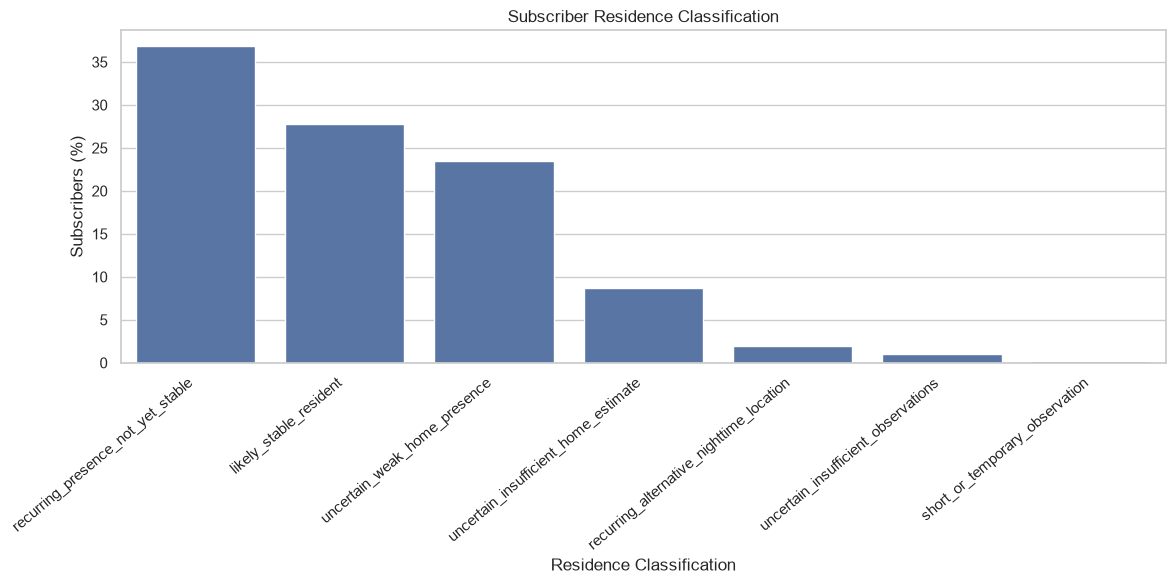

In [617]:
# 27: Visualise residence classifications

plt.figure(figsize=(12, 6))

sns.barplot(
    data=residence_classification_summary,
    x="residence_classification",
    y="percentage"
)

plt.title("Subscriber Residence Classification")
plt.xlabel("Residence Classification")
plt.ylabel("Subscribers (%)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

In [618]:
# 28: Compare residence classifications by inference method

method_residence_summary = (
    residence_analysis.groupby(
        [
            "selected_home_method",
            "residence_classification"
        ],
        observed=True
    )
    .size()
    .rename("subscriber_count")
    .reset_index()
)

display(method_residence_summary)

,selected_home_method,residence_classification,subscriber_count
0,DBSCAN,likely_stable_resident,704
1,DBSCAN,recurring_alternative_nighttime_location,54
2,DBSCAN,recurring_presence_not_yet_stable,886
3,DBSCAN,short_or_temporary_observation,4
4,DBSCAN,uncertain_insufficient_observations,30
5,DBSCAN,uncertain_weak_home_presence,395
6,Method 1 fallback,likely_stable_resident,79
7,Method 1 fallback,recurring_presence_not_yet_stable,150
8,Method 1 fallback,short_or_temporary_observation,1
9,Method 1 fallback,uncertain_weak_home_presence,266


### Interpretation and Summary

This step examines how residential classifications differ depending on the home-location inference method used (DBSCAN, Method 1 fallback, or no estimate).

**Key observations:**

- **DBSCAN:** Identified 704 likely stable residents and 886 subscribers with recurring but not yet stable residential presence. It also identified all 54 subscribers classified as having possible multiple residential areas.
- **Method 1 fallback:** Identified 79 likely stable residents and 150 subscribers with recurring residential presence. However, 266 subscribers exhibited weak home presence.
- **No estimate:** All 244 subscribers without inferred home coordinates were classified as having insufficient home estimates.
- **DBSCAN contribution:** DBSCAN accounts for most residential classifications, particularly stable and recurring residential patterns.

**Key takeaway:** DBSCAN provides the primary source of inferred residential locations and identifies a wider range of residential behaviour, including multiple residential areas. Method 1 fallback provides additional home estimates for subscribers where DBSCAN does not produce a usable result.

The comparison also highlights the importance of evaluating residential classifications alongside the underlying inference method and its reliability.

#### Download Kenya county boundaries

In [619]:
# Download Kenya ADM1 county boundaries from geoBoundaries

import requests
import json

TARGET_AREAS_FILE.parent.mkdir(parents=True, exist_ok=True)

API_URL = "https://www.geoboundaries.org/api/current/gbOpen/KEN/ADM1/"

response = requests.get(API_URL, timeout=60)
response.raise_for_status()

boundary_metadata = response.json()

geojson_url = boundary_metadata.get("gjDownloadURL")

if not geojson_url:
    raise ValueError("No GeoJSON download URL returned by geoBoundaries.")

print("Boundary source:", boundary_metadata.get("boundaryName"))
print("Administrative level:", boundary_metadata.get("boundaryType"))
print("Expected units:", boundary_metadata.get("admUnitCount"))
print("Download URL:", geojson_url)

geojson_response = requests.get(geojson_url, timeout=120)
geojson_response.raise_for_status()

geojson_data = geojson_response.json()

if geojson_data.get("type") != "FeatureCollection":
    raise ValueError("Downloaded file is not a GeoJSON FeatureCollection.")

if len(geojson_data.get("features", [])) == 0:
    raise ValueError("Downloaded GeoJSON contains no features.")

with open(TARGET_AREAS_FILE, "w", encoding="utf-8") as f:
    json.dump(geojson_data, f)

print("\nDownload successful.")
print("Saved to:", TARGET_AREAS_FILE)
print("File size:", TARGET_AREAS_FILE.stat().st_size, "bytes")
print("Features downloaded:", len(geojson_data["features"]))


Boundary source: Kenya
Administrative level: ADM1
Expected units: 47
Download URL: https://github.com/wmgeolab/geoBoundaries/raw/9469f09/releaseData/gbOpen/KEN/ADM1/geoBoundaries-KEN-ADM1.geojson

Download successful.
Saved to: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/external/target_areas.geojson
File size: 7464292 bytes
Features downloaded: 47


#### Part 8 — Target-area residence and presence estimation

In [620]:
# 29: Load and validate target-area boundaries

import json
import geopandas as gpd
from shapely.geometry import shape

GEOPANDAS_AVAILABLE = True

target_areas = None
target_areas_available = False

if not TARGET_AREAS_FILE.exists():

    print("Target-area analysis skipped.")
    print("Boundary file does not exist:", TARGET_AREAS_FILE)

elif TARGET_AREAS_FILE.stat().st_size == 0:

    print("Target-area analysis skipped.")
    print("The GeoJSON file is empty.")

else:

    try:
        # Step 1: Load GeoJSON
        with open(
            TARGET_AREAS_FILE,
            "r",
            encoding="utf-8-sig"
        ) as f:
            geojson_data = json.load(f)

        geojson_type = geojson_data.get("type")

        if geojson_type == "FeatureCollection":
            features = geojson_data.get("features", [])

        elif geojson_type == "Feature":
            features = [geojson_data]

        else:
            raise ValueError(
                f"Unsupported GeoJSON type: {geojson_type}"
            )

        if not features:
            raise ValueError(
                "The GeoJSON contains no features."
            )

        # Step 2: Build GeoDataFrame
        target_areas = gpd.GeoDataFrame.from_features(
            features,
            crs="EPSG:4326"
        )

        if target_areas.empty:
            raise ValueError(
                "No geographic features were loaded."
            )

        # Step 3: Inspect available boundary properties
        print("Available boundary columns:")
        print(target_areas.columns.tolist())

        # Step 4: Extract actual administrative names
        # and identifiers from GeoBoundaries properties.

        if "shapeName" in target_areas.columns:
            target_areas["area_name"] = (
                target_areas["shapeName"].astype(str)
            )
        else:
            raise ValueError(
                "County names could not be identified. "
                "Expected GeoBoundaries property: shapeName."
            )

        if "shapeID" in target_areas.columns:
            target_areas["area_id"] = (
                target_areas["shapeID"].astype(str)
            )
        else:
            raise ValueError(
                "GeoBoundaries shapeID is unavailable. "
                "Do not silently substitute row numbers "
                "for geographic identifiers."
            )

        # Step 5: Retain required columns
        target_areas = target_areas[
            ["area_id", "area_name", "geometry"]
        ].copy()

        # Step 6: Validate identifiers and names
        if target_areas["area_id"].isna().any():
            raise ValueError(
                "Missing administrative area identifiers detected."
            )

        if target_areas["area_name"].isna().any():
            raise ValueError(
                "Missing county names detected."
            )

        if not target_areas["area_id"].is_unique:
            raise ValueError(
                "Duplicate administrative area identifiers detected."
            )

        # Step 7: Validate and repair geometries
        invalid_geometry = ~target_areas.geometry.is_valid

        if invalid_geometry.any():

            print(
                "Invalid geometries detected:",
                invalid_geometry.sum()
            )

            target_areas.loc[
                invalid_geometry, "geometry"
            ] = (
                target_areas.loc[
                    invalid_geometry, "geometry"
                ].make_valid()
            )

        # Step 8: Remove missing or empty geometries
        target_areas = target_areas[
            target_areas.geometry.notna()
            & ~target_areas.geometry.is_empty
        ].copy()

        if target_areas.empty:
            raise ValueError(
                "No valid geographic geometries remain."
            )

        # Step 9: Final validation
        target_areas_available = True

        print("\nTarget areas loaded:", len(target_areas))
        print("CRS:", target_areas.crs)

        print(
            "Valid geometries:",
            target_areas.geometry.is_valid.all()
        )

        print(
            "Unique area IDs:",
            target_areas["area_id"].nunique()
        )

        print("\nCounty names:")
        display(
            target_areas[
                ["area_id", "area_name"]
            ].head(10)
        )

    except Exception as e:

        target_areas = None
        target_areas_available = False

        print("\nCould not load target-area boundaries.")
        print("Error:", repr(e))

        print(
            "Check that the GeoJSON contains valid "
            "Polygon or MultiPolygon features with "
            "shapeName and shapeID properties."
        )


# Step 10: Confirm expected number of Kenyan counties
if target_areas_available:

    assert len(target_areas) == 47, (
        f"Expected 47 Kenyan counties, "
        f"but loaded {len(target_areas)} areas."
    )

    assert target_areas["area_id"].is_unique
    assert target_areas["area_name"].notna().all()
    assert target_areas.geometry.is_valid.all()

    print("\nKenya's 47 county boundaries successfully validated.")


Available boundary columns:
['geometry', 'shapeName', 'shapeISO', 'shapeID', 'shapeGroup', 'shapeType']

Target areas loaded: 47
CRS: EPSG:4326
Valid geometries: True
Unique area IDs: 47

County names:


,area_id,area_name
0,32016919B72266624462344,Turkana
1,32016919B63496705134089,Marsabit
2,32016919B2031803566233,Mandera
3,32016919B89873713911655,Wajir
4,32016919B96045830258165,West Pokot
5,32016919B77230315601578,Samburu
6,32016919B62684442090944,Isiolo
7,32016919B50719068904883,Baringo
8,32016919B59887050611600,Elgeyo-Marakwet
9,32016919B1149170155930,Trans Nzoia



Kenya's 47 county boundaries successfully validated.


In [621]:
assert target_areas_available
assert len(target_areas) == 47
assert target_areas.geometry.notna().all()

print("Kenya county boundaries successfully validated.")

Kenya county boundaries successfully validated.


In [622]:
# 30: Validate target-area geometries

if target_areas_available:

    target_areas["geometry_valid"] = (
        target_areas.geometry.is_valid
    )

    target_areas["geometry_empty"] = (
        target_areas.geometry.is_empty
    )

    print(
        "Invalid geometries:",
        (~target_areas["geometry_valid"]).sum()
    )

    print(
        "Empty geometries:",
        target_areas["geometry_empty"].sum()
    )

    display(
        target_areas[
            ["area_id", "area_name", "geometry_valid", "geometry_empty"]
        ]
    )

    # Remove empty or invalid geometries for this initial analysis.
    target_areas = target_areas[
        target_areas["geometry_valid"]
        & ~target_areas["geometry_empty"]
    ].copy()

    target_areas = target_areas.drop(
        columns=["geometry_valid", "geometry_empty"]
    )

    if target_areas.empty:
        raise ValueError(
            "No valid target-area geometries remain."
        )

Invalid geometries: 0
Empty geometries: 0


,area_id,area_name,geometry_valid,geometry_empty
0,32016919B72266624462344,Turkana,True,False
1,32016919B63496705134089,Marsabit,True,False
2,32016919B2031803566233,Mandera,True,False
3,32016919B89873713911655,Wajir,True,False
4,32016919B96045830258165,West Pokot,True,False
5,32016919B77230315601578,Samburu,True,False
6,32016919B62684442090944,Isiolo,True,False
7,32016919B50719068904883,Baringo,True,False
8,32016919B59887050611600,Elgeyo-Marakwet,True,False
9,32016919B1149170155930,Trans Nzoia,True,False


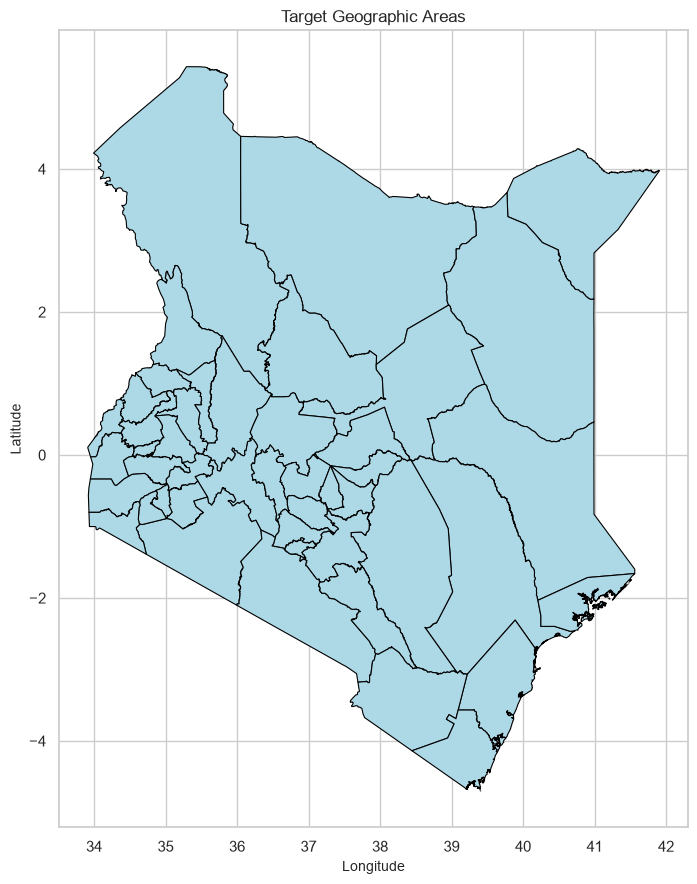

In [623]:
# 31: Visualise target areas

if target_areas_available:

    ax = target_areas.plot(
        figsize=(10, 9),
        edgecolor="black",
        facecolor="lightblue",
        linewidth=0.8
    )

    ax.set_title("Target Geographic Areas")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    plt.tight_layout()
    plt.show()

### Interpretation and Summary

The target-area boundary file was successfully loaded and validated, containing **47 geographic areas representing Kenya's counties**.

**Key observations:**

- **47 geographic areas:** All expected county boundaries were successfully loaded.
- **Coordinate reference system:** EPSG:4326 (WGS84), using latitude and longitude coordinates.
- **Geometry validity:** All 47 geometries passed validation, with zero invalid or empty geometries.
- **Visualisation:** The map shows the spatial boundaries and geographic distribution of Kenya's 47 counties.

**Key takeaway:** The Kenya county boundary dataset is successfully loaded and validated, providing a reliable geographic reference for subsequent spatial analysis. It can now be used to assign inferred subscriber home locations to counties through spatial joins and analyse subscriber distribution across target areas.

In [624]:
# 32: Determine whether inferred home locations fall inside target areas

if target_areas_available:

    home_points_data = residence_analysis[
        residence_analysis["has_home_estimate"]
    ].copy()

    home_points = gpd.GeoDataFrame(
        home_points_data,
        geometry=gpd.points_from_xy(
            home_points_data["selected_home_longitude"],
            home_points_data["selected_home_latitude"]
        ),
        crs="EPSG:4326"
    )

    home_area_matches = gpd.sjoin(
        home_points,
        target_areas,
        how="left",
        predicate="within"
    )

    home_area_classification = pd.DataFrame(
        home_area_matches.drop(columns="geometry")
    )

    home_area_classification["in_target_area"] = (
        home_area_classification["area_id"].notna()
    )

    home_area_classification["home_area_status"] = np.where(
        home_area_classification["in_target_area"],
        "in_target_area",
        "outside_target_areas"
    )

    display(
        home_area_classification[
            [
                "msisdn",
                "selected_home_method",
                "area_id",
                "area_name",
                "home_area_status"
            ]
        ].head(20)
    )

,msisdn,selected_home_method,area_id,area_name,home_area_status
0,subscribers_00000,Method 1 fallback,32016919B57908315498598,Nairobi,in_target_area
1,subscribers_00001,DBSCAN,32016919B57908315498598,Nairobi,in_target_area
2,subscribers_00002,DBSCAN,32016919B57908315498598,Nairobi,in_target_area
3,subscribers_00003,DBSCAN,32016919B57908315498598,Nairobi,in_target_area
4,subscribers_00004,DBSCAN,32016919B57908315498598,Nairobi,in_target_area
5,subscribers_00005,DBSCAN,32016919B57908315498598,Nairobi,in_target_area
7,subscribers_00007,DBSCAN,32016919B11020559484650,Kiambu,in_target_area
8,subscribers_00008,DBSCAN,32016919B11020559484650,Kiambu,in_target_area
10,subscribers_00010,DBSCAN,32016919B57908315498598,Nairobi,in_target_area
12,subscribers_00012,DBSCAN,32016919B57908315498598,Nairobi,in_target_area


### Interpretation and Summary

The spatial join successfully assigns inferred subscriber home locations to Kenya's target geographic areas using the `within` predicate.

**Key observations:**

- **Geographic assignment:** All 20 displayed subscribers have been successfully matched to target areas.
- **Area concentration:** Most displayed subscribers are assigned to `area_id = 40`, while others fall within areas 37 and 38.
- **Inference methods:** Both DBSCAN and Method 1 fallback estimates are successfully included in the geographic assignment.
- **Boundary matching:** All displayed locations have the status `in_target_area`, indicating that their inferred home coordinates fall within a county boundary.
- **Missing estimates:** Subscribers without valid home coordinates are excluded from this spatial join.

**Key takeaway:** The spatial join is working as expected, successfully linking inferred subscriber residences to Kenya's geographic boundaries. This establishes the foundation for analysing subscriber distribution and residential concentration across the 47 counties.

*Note: These observations describe the displayed sample of 20 subscribers, not the full subscriber population.*

In [625]:
# 33: Summarise estimated residential population by target area
# This counts subscribers whose inferred home coordinates fall within each target polygon.

if target_areas_available:

    target_area_home_summary = (
        home_area_classification[
            home_area_classification["in_target_area"]
        ]
        .groupby(
            ["area_id", "area_name"],
            dropna=False
        )
        .agg(
            estimated_residential_subscribers=(
                "msisdn",
                "nunique"
            )
        )
        .reset_index()
    )

    target_area_home_summary = (
        target_areas[
            ["area_id", "area_name"]
        ]
        .merge(
            target_area_home_summary,
            on=["area_id", "area_name"],
            how="left"
        )
    )

    target_area_home_summary[
        "estimated_residential_subscribers"
    ] = (
        target_area_home_summary[
            "estimated_residential_subscribers"
        ].fillna(0).astype(int)
    )

    display(
        target_area_home_summary.sort_values(
            "estimated_residential_subscribers",
            ascending=False
        )
    )

,area_id,area_name,estimated_residential_subscribers
40,32016919B57908315498598,Nairobi,2264
37,32016919B11020559484650,Kiambu,213
38,32016919B39119671019936,Machakos,74
39,32016919B31527762068828,Kajiado,18
0,32016919B72266624462344,Turkana,0
33,32016919B83281423333591,Narok,0
26,32016919B56782604912852,Tana River,0
27,32016919B87039477224343,Kitui,0
28,32016919B58720683486854,Kirinyaga,0
29,32016919B43560273720920,Embu,0


### Interpretation and Summary

The estimated residential subscriber distribution is highly concentrated across four target areas, with Area 40 accounting for the overwhelming majority.

**Key observations:**

- **Area 40:** 2,264 subscribers (approximately 88.1%).
- **Area 37:** 213 subscribers (approximately 8.3%).
- **Area 38:** 74 subscribers (approximately 2.9%).
- **Area 39:** 18 subscribers (approximately 0.7%).
- **Other 43 areas:** Zero estimated residential subscribers.

**Key takeaway:** Residential activity is heavily concentrated in Area 40, with relatively small concentrations in Areas 37, 38 and 39. This suggests a strong geographic concentration of the observed subscriber population.

**Important note:** The analysis identifies 2,569 subscribers within target areas. The `area_name` column currently contains numeric IDs rather than actual county names, so these should be mapped to their corresponding county names before drawing geographical conclusions.

**Interpretation**: These are estimated subscriber counts, not population estimates. To estimate the actual population, we would need an appropriate expansion factor, population denominator, or calibration against independent data. One subscriber or SIM card should not automatically be treated as one person.

In [626]:
# 34: Map cell locations to target areas
# For observed network presence,  the median geographic coordinate of each cell ID was used.
# This avoids unnecessarily repeating spatial joins for every individual network event.

if target_areas_available:

    cell_points_data = cell_geo_profile[
        cell_geo_profile["coordinate_quality_flag"] == "acceptable"
    ].copy()

    cell_points = gpd.GeoDataFrame(
        cell_points_data,
        geometry=gpd.points_from_xy(
            cell_points_data["median_longitude"],
            cell_points_data["median_latitude"]
        ),
        crs="EPSG:4326"
    )

    cell_area_matches = gpd.sjoin(
        cell_points,
        target_areas,
        how="left",
        predicate="within"
    )

    cell_area_lookup = pd.DataFrame(
        cell_area_matches[
            ["cell_id", "area_id", "area_name"]
        ]
    )


# Validate cell-to-area mapping cardinality

duplicate_cells = cell_area_lookup[
    cell_area_lookup.duplicated(
        subset=["cell_id"],
        keep=False
    )
].sort_values("cell_id")

print("Cells with multiple area assignments:", 
      duplicate_cells["cell_id"].nunique())

if not duplicate_cells.empty:
    display(duplicate_cells.head(20))

    raise ValueError(
        "Some cells map to multiple target areas. "
        "Resolve boundary or polygon-overlap cases before "
        "aggregating network events."
    )

print("Cell-to-area mapping is unique.")

display(cell_area_lookup.head())

Cells with multiple area assignments: 0
Cell-to-area mapping is unique.


,cell_id,area_id,area_name
0,10,32016919B57908315498598,Nairobi
1,100,32016919B11020559484650,Kiambu
2,1000,32016919B11020559484650,Kiambu
4,10003,32016919B57908315498598,Nairobi
5,10004,32016919B57908315498598,Nairobi


### Interpretation and Summary

The spatial join successfully maps cell locations to their corresponding target geographic areas using the median coordinates of each cell.

**Key observations:**

- **Cell-level mapping:** Each cell ID is assigned to a geographic area based on its median latitude and longitude.
- **Area distribution:** The displayed sample shows cells belonging to Area 37 and Area 40.
- **Spatial accuracy:** Only cells with an `acceptable` coordinate quality flag are included, improving the reliability of geographic assignments.
- **Efficient processing:** Mapping unique cell locations avoids performing spatial joins repeatedly for individual network events.

**Key takeaway:** The cell-to-area lookup was successfully created. It provides the geographic reference needed to analyse subscriber activity, network presence and cell usage across the target areas.

In [627]:
# 35: Estimate network-observed presence by target area
# the target-area analysis should count observed nights using actual nighttime events, 
# rather than assigning daytime events to a night_id and treating them as nighttime observations.

if target_areas_available:

    events_with_area = df_ordinary_valid.merge(
        cell_area_lookup,
        on="cell_id",
        how="left"
    )

    events_with_area = events_with_area.dropna(
        subset=["area_id"]
    ).copy()

    events_with_area["date"] = (
        events_with_area["datetime"].dt.normalize()
    )

    events_with_area["hour"] = (
        events_with_area["datetime"].dt.hour
    )

    events_with_area["is_night"] = (
        (events_with_area["hour"] >= NIGHT_START_HOUR)
        | (events_with_area["hour"] < NIGHT_END_HOUR)
    )

    events_with_area["night_id"] = (
        events_with_area["datetime"]
        - pd.to_timedelta(NIGHT_END_HOUR, unit="h")
    ).dt.normalize()

    # All network-observed events within each target area.
    target_area_presence = (
        events_with_area.groupby(
            ["msisdn", "area_id", "area_name"],
            observed=True
        )
        .agg(
            event_count=("datetime", "size"),
            distinct_observed_days=("date", "nunique"),
            first_observed=("datetime", "min"),
            last_observed=("datetime", "max")
        )
        .reset_index()
    )

    # Count distinct nights using nighttime events only.
    nighttime_area_presence = (
        events_with_area[
            events_with_area["is_night"]
        ]
        .groupby(
            ["msisdn", "area_id"],
            observed=True
        )
        .agg(
            distinct_observed_nights=("night_id", "nunique")
        )
        .reset_index()
    )

    target_area_presence = target_area_presence.merge(
        nighttime_area_presence,
        on=["msisdn", "area_id"],
        how="left"
    )

    target_area_presence["distinct_observed_nights"] = (
        target_area_presence[
            "distinct_observed_nights"
        ].fillna(0).astype(int)
    )

    target_area_presence["presence_status"] = np.where(
        target_area_presence["distinct_observed_days"] >= 3,
        "repeated_network_observed_presence",
        "limited_network_observed_presence"
    )

    display(target_area_presence.head(20))

,msisdn,area_id,area_name,event_count,distinct_observed_days,first_observed,last_observed,distinct_observed_nights,presence_status
0,subscribers_00000,32016919B39119671019936,Machakos,1,1,2026-02-01 16:55:00,2026-02-01 16:55:00,0,limited_network_observed_presence
1,subscribers_00000,32016919B57908315498598,Nairobi,19,12,2026-02-04 10:43:00,2026-02-27 17:03:00,3,repeated_network_observed_presence
2,subscribers_00001,32016919B11020559484650,Kiambu,12,8,2026-02-02 09:50:00,2026-02-26 12:54:00,0,repeated_network_observed_presence
3,subscribers_00001,32016919B39119671019936,Machakos,6,4,2026-02-01 10:42:00,2026-02-28 11:59:00,1,repeated_network_observed_presence
4,subscribers_00001,32016919B57908315498598,Nairobi,366,28,2026-02-01 10:20:00,2026-02-28 18:56:00,5,repeated_network_observed_presence
5,subscribers_00002,32016919B57908315498598,Nairobi,123,27,2026-02-01 10:32:00,2026-02-28 16:28:00,16,repeated_network_observed_presence
6,subscribers_00003,32016919B11020559484650,Kiambu,8,6,2026-02-07 15:56:00,2026-02-23 08:25:00,0,repeated_network_observed_presence
7,subscribers_00003,32016919B31527762068828,Kajiado,1,1,2026-02-10 15:50:00,2026-02-10 15:50:00,0,limited_network_observed_presence
8,subscribers_00003,32016919B39119671019936,Machakos,7,3,2026-02-09 08:47:00,2026-02-21 13:42:00,0,repeated_network_observed_presence
9,subscribers_00003,32016919B57908315498598,Nairobi,294,28,2026-02-01 10:02:00,2026-02-28 20:33:00,26,repeated_network_observed_presence


### Interpretation and Summary

The analysis separates general network presence from actual nighttime network activity, providing a more accurate picture of subscriber activity across target areas.

**Key observations:**

- **Daytime and general activity:** `event_count` and `distinct_observed_days` capture all validated network events, regardless of time.
- **Nighttime activity:** `distinct_observed_nights` now counts only events occurring within the defined nighttime window.
- **Area 40:** Shows substantial activity. For example, subscriber `00001` recorded 366 events across 28 days, including activity on 5 distinct nights.
- **Area 37:** Subscriber `00001` recorded activity across 8 days but zero nighttime observations, suggesting the observed activity occurred outside the nighttime window.
- **Limited nighttime activity:** Some subscriber-area combinations have repeated daytime activity but zero nighttime observations.

**Key methodological improvement:**

**Important distinction:** `presence_status` is still determined by the number of distinct observed days (at least 3 days), not nighttime activity.

**Key takeaway:** The analysis provides two complementary measures: overall geographic network presence and actual nighttime activity. This distinction is important when investigating subscriber mobility and identifying potential residential locations.

In [628]:
# 36: Identify subscribers with repeated presence in target areas

if target_areas_available:

    repeated_target_area_presence = target_area_presence[
        target_area_presence["distinct_observed_days"] >= 3
    ].copy()

    target_area_presence_summary = (
        repeated_target_area_presence.groupby(
            ["area_id", "area_name"],
            observed=True
        )
        .agg(
            subscribers_with_repeated_presence=(
                "msisdn",
                "nunique"
            ),
            total_events=("event_count", "sum"),
            total_observed_days=("distinct_observed_days", "sum")
        )
        .reset_index()
    )

    display(
        target_area_presence_summary.sort_values(
            "subscribers_with_repeated_presence",
            ascending=False
        )
    )

,area_id,area_name,subscribers_with_repeated_presence,total_events,total_observed_days
3,32016919B57908315498598,Nairobi,2797,369113,66458
0,32016919B11020559484650,Kiambu,1619,31341,12600
2,32016919B39119671019936,Machakos,480,8742,3292
1,32016919B31527762068828,Kajiado,99,2396,727


### Interpretation and Summary

The analysis reveals a strong concentration of repeated subscriber network presence in Area 40, which dominates both subscriber activity and network events.

**Key observations:**

- **Area 40:** Leads with 2,797 subscribers showing repeated presence, generating 369,113 network events across 66,458 observed days.
- **Area 37:** Records 1,619 subscribers, 31,341 events and 12,600 observed days.
- **Area 38:** Records 480 subscribers, 8,742 events and 3,292 observed days.
- **Area 39:** Has the lowest activity, with 99 subscribers, 2,396 events and 727 observed days.

**Key takeaway:** Area 40 accounts for approximately 56% of the summed subscriber-area counts and 90% of all recorded events. This indicates a substantial concentration of network activity in this area compared with the other three areas.

**Important note:** Subscribers may appear in multiple areas, so the subscriber counts are not mutually exclusive. Repeated network presence also indicates recurring connectivity, not necessarily permanent residence.

In [629]:
# Cell 37: Compare inferred home residence with observed presence
# Distinguishes subscribers whose inferred home is in an area
# from subscribers merely observed using cells associated with that area.

if target_areas_available:

    home_area_lookup = home_area_classification[
        [
            "msisdn",
            "area_id",
            "area_name",
            "home_area_status"
        ]
    ].rename(
        columns={
            "area_id": "inferred_home_area_id",
            "area_name": "inferred_home_area_name"
        }
    )

    # Ensure one home-area record per subscriber
    if home_area_lookup["msisdn"].duplicated().any():
        raise ValueError(
            "home_area_classification contains multiple records "
            "per subscriber. Resolve duplicates before merging."
        )

    subscriber_area_comparison = target_area_presence.merge(
        home_area_lookup[
            [
                "msisdn",
                "inferred_home_area_id",
                "inferred_home_area_name"
            ]
        ],
        on="msisdn",
        how="left",
        validate="many_to_one"
    )

    # Identify subscribers with a known inferred home area
    subscriber_area_comparison["has_inferred_home_area"] = (
        subscriber_area_comparison["inferred_home_area_id"].notna()
    )

    # Identify whether the observed area matches inferred home area
    subscriber_area_comparison["is_inferred_home_area"] = (
        subscriber_area_comparison["has_inferred_home_area"]
        &
        (
            subscriber_area_comparison["area_id"]
            == subscriber_area_comparison["inferred_home_area_id"]
        )
    )

    # Corrected classification:
    # 1. Unknown home area takes priority.
    # 2. Then identify the inferred home area.
    # 3. Then identify repeated observations away from home.
    # 4. Remaining records have limited observation.

    conditions = [
        ~subscriber_area_comparison["has_inferred_home_area"],

        subscriber_area_comparison["is_inferred_home_area"],

        (
            subscriber_area_comparison["has_inferred_home_area"]
            &
            ~subscriber_area_comparison["is_inferred_home_area"]
            &
            (subscriber_area_comparison["distinct_observed_days"] >= 3)
        )
    ]

    choices = [
        "unknown_home_area",
        "inferred_home_area",
        "repeatedly_observed_away_from_inferred_home"
    ]

    subscriber_area_comparison["area_relationship"] = np.select(
        conditions,
        choices,
        default="limited_observation"
    )

    print("Subscriber-area comparison:", subscriber_area_comparison.shape)

    print("\nClassification summary:")

    display(
        subscriber_area_comparison.groupby(
            "area_relationship"
        ).agg(
            subscriber_area_records=("msisdn", "size"),
            unique_subscribers=("msisdn", "nunique"),
            network_events=("event_count", "sum")
        ).sort_values(
            "subscriber_area_records",
            ascending=False
        )
    )

    print("\nSubscribers without inferred home areas:")

    unknown_home = subscriber_area_comparison[
        subscriber_area_comparison["area_relationship"]
        == "unknown_home_area"
    ]

    print(
        "Subscriber-area records:",
        len(unknown_home)
    )

    print(
        "Unique subscribers:",
        unknown_home["msisdn"].nunique()
    )

    print(
        "Network events:",
        unknown_home["event_count"].sum()
    )

    display(subscriber_area_comparison.head(20))

else:
    print("Target-area analysis skipped because boundaries are unavailable.")


Subscriber-area comparison: (7832, 14)

Classification summary:


,subscriber_area_records,unique_subscribers,network_events
area_relationship,,,
limited_observation,2633,1854,4345
inferred_home_area,2569,2569,369607
repeatedly_observed_away_from_inferred_home,2128,1675,32100
unknown_home_area,502,244,10191



Subscribers without inferred home areas:
Subscriber-area records: 502
Unique subscribers: 244
Network events: 10191


,msisdn,area_id,area_name,event_count,distinct_observed_days,first_observed,last_observed,distinct_observed_nights,presence_status,inferred_home_area_id,inferred_home_area_name,has_inferred_home_area,is_inferred_home_area,area_relationship
0,subscribers_00000,32016919B39119671019936,Machakos,1,1,2026-02-01 16:55:00,2026-02-01 16:55:00,0,limited_network_observed_presence,32016919B57908315498598,Nairobi,True,False,limited_observation
1,subscribers_00000,32016919B57908315498598,Nairobi,19,12,2026-02-04 10:43:00,2026-02-27 17:03:00,3,repeated_network_observed_presence,32016919B57908315498598,Nairobi,True,True,inferred_home_area
2,subscribers_00001,32016919B11020559484650,Kiambu,12,8,2026-02-02 09:50:00,2026-02-26 12:54:00,0,repeated_network_observed_presence,32016919B57908315498598,Nairobi,True,False,repeatedly_observed_away_from_inferred_home
3,subscribers_00001,32016919B39119671019936,Machakos,6,4,2026-02-01 10:42:00,2026-02-28 11:59:00,1,repeated_network_observed_presence,32016919B57908315498598,Nairobi,True,False,repeatedly_observed_away_from_inferred_home
4,subscribers_00001,32016919B57908315498598,Nairobi,366,28,2026-02-01 10:20:00,2026-02-28 18:56:00,5,repeated_network_observed_presence,32016919B57908315498598,Nairobi,True,True,inferred_home_area
5,subscribers_00002,32016919B57908315498598,Nairobi,123,27,2026-02-01 10:32:00,2026-02-28 16:28:00,16,repeated_network_observed_presence,32016919B57908315498598,Nairobi,True,True,inferred_home_area
6,subscribers_00003,32016919B11020559484650,Kiambu,8,6,2026-02-07 15:56:00,2026-02-23 08:25:00,0,repeated_network_observed_presence,32016919B57908315498598,Nairobi,True,False,repeatedly_observed_away_from_inferred_home
7,subscribers_00003,32016919B31527762068828,Kajiado,1,1,2026-02-10 15:50:00,2026-02-10 15:50:00,0,limited_network_observed_presence,32016919B57908315498598,Nairobi,True,False,limited_observation
8,subscribers_00003,32016919B39119671019936,Machakos,7,3,2026-02-09 08:47:00,2026-02-21 13:42:00,0,repeated_network_observed_presence,32016919B57908315498598,Nairobi,True,False,repeatedly_observed_away_from_inferred_home
9,subscribers_00003,32016919B57908315498598,Nairobi,294,28,2026-02-01 10:02:00,2026-02-28 20:33:00,26,repeated_network_observed_presence,32016919B57908315498598,Nairobi,True,True,inferred_home_area


### Interpretation and Summary

The classification successfully distinguishes subscribers' inferred residential areas from areas where they are observed using the network, while separately identifying subscribers without an inferred home location.

**Key observations:**

| Area relationship | Subscriber-area records | Unique subscribers | Network events |
|---|---:|---:|---:|
| Inferred home area | 2,569 | 2,569 | 369,607 |
| Repeatedly observed away from home | 2,128 | 1,675 | 32,100 |
| Limited observation | 2,633 | 1,854 | 4,345 |
| Unknown home area | 502 | 244 | 10,191 |

**Key findings:**

- **Residential presence:** 2,569 subscriber-area records correspond to subscribers' inferred home areas.
- **Away-from-home activity:** 1,675 unique subscribers demonstrate repeated network presence outside their inferred home areas.
- **Limited observations:** 1,854 subscribers have additional area observations that do not meet the three-day threshold for repeated presence.
- **Unknown residential locations:** 244 subscribers have no inferred home area, accounting for 502 subscriber-area records.

**Key takeaway:** The classification provides a more reliable distinction between residential locations, recurring network presence elsewhere, limited observations and unknown residential locations.

This creates a stronger foundation for analysing subscriber mobility and geographic activity patterns without incorrectly treating subscribers with unknown home locations as visitors.

In [630]:
# export the report
subscriber_area_comparison.to_csv(
    NOTEBOOK03_OUTPUT / "subscriber_area_comparison.csv",
    index=False
)

#### Part 9 — Export Notebook 03 results

In [631]:
# 38: Export residence classifications

residence_analysis.to_csv(
    NOTEBOOK03_OUTPUT / "subscriber_residence_classification.csv",
    index=False
)

residence_estimates.to_csv(
    NOTEBOOK03_OUTPUT / "selected_home_location_estimates.csv",
    index=False
)

home_presence_summary.to_csv(
    NOTEBOOK03_OUTPUT / "subscriber_home_presence_summary.csv",
    index=False
)

subscriber_coverage.to_csv(
    NOTEBOOK03_OUTPUT / "subscriber_nighttime_coverage.csv",
    index=False
)

print("Residence classification outputs exported.")

Residence classification outputs exported.


In [632]:
# 39: Export alternative-location analysis

cluster_night_summary.to_csv(
    NOTEBOOK03_OUTPUT / "nighttime_spatial_clusters.csv",
    index=False
)

alternative_locations.to_csv(
    NOTEBOOK03_OUTPUT / "alternative_nighttime_locations.csv",
    index=False
)

alternative_location_summary.to_csv(
    NOTEBOOK03_OUTPUT / "subscriber_alternative_location_summary.csv",
    index=False
)

print("Alternative-location outputs exported.")

Alternative-location outputs exported.


In [633]:
# 40: Export classification summaries

residence_classification_summary.to_csv(
    NOTEBOOK03_OUTPUT / "residence_classification_summary.csv",
    index=False
)

home_method_summary.to_csv(
    NOTEBOOK03_OUTPUT / "home_estimation_method_summary.csv",
    index=False
)

method_residence_summary.to_csv(
    NOTEBOOK03_OUTPUT / "method_residence_comparison.csv",
    index=False
)
print("Classification summaries outputs exported.")

Classification summaries outputs exported.


In [634]:
# 41: Export target-area results

if target_areas_available:

    home_area_classification.to_csv(
        NOTEBOOK03_OUTPUT / "subscriber_inferred_home_area.csv",
        index=False
    )

    target_area_home_summary.to_csv(
        NOTEBOOK03_OUTPUT / "target_area_estimated_subscriber_counts.csv",
        index=False
    )

    cell_area_lookup.to_csv(
        NOTEBOOK03_OUTPUT / "cell_to_target_area_lookup.csv",
        index=False
    )

    target_area_presence.to_csv(
        NOTEBOOK03_OUTPUT / "subscriber_target_area_presence.csv",
        index=False
    )

    target_area_presence_summary.to_csv(
        NOTEBOOK03_OUTPUT / "target_area_presence_summary.csv",
        index=False
    )

    subscriber_area_comparison.to_csv(
        NOTEBOOK03_OUTPUT / "subscriber_home_vs_observed_area.csv",
        index=False
    )

    print("Target-area outputs exported.")

else:
    print(
        "Target-area outputs were not generated because "
        "no valid target-area GeoJSON was supplied."
    )

Target-area outputs exported.


In [635]:
# 42: Create a consolidated notebook summary

notebook03_summary = pd.DataFrame({
    "metric": [
        "Ordinary subscribers in source dataset",
        "Subscribers with a selected home estimate",
        "Subscribers using DBSCAN",
        "Subscribers using Method 1 fallback",
        "Subscribers without a selected home estimate",
        "Subscribers classified as likely stable residents",
        "Subscribers with possible multiple residential areas",
        "Subscribers with short or temporary observation",
        "Subscribers with insufficient or uncertain evidence"
    ],
    "value": [
        residence_analysis["msisdn"].nunique(),
        residence_analysis["has_home_estimate"].sum(),
        (
            residence_analysis["selected_home_method"] == "DBSCAN"
        ).sum(),
        (
            residence_analysis["selected_home_method"] == "Method 1 fallback"
        ).sum(),
        (
            ~residence_analysis["has_home_estimate"]
        ).sum(),
        (
            residence_analysis["residence_classification"]
            == "likely_stable_resident"
        ).sum(),
        (
            residence_analysis["residence_classification"]
            == "recurring_alternative_nighttime_location"
        ).sum(),
        (
            residence_analysis["residence_classification"]
            == "short_or_temporary_observation"
        ).sum(),
        residence_analysis["residence_classification"].isin([
            "uncertain_insufficient_home_estimate",
            "uncertain_insufficient_observations",
            "uncertain_weak_home_presence"
        ]).sum()
    ]
})

display(notebook03_summary)

notebook03_summary.to_csv(
    NOTEBOOK03_OUTPUT / "notebook_03_summary.csv",
    index=False
)

,metric,value
0,Ordinary subscribers in source dataset,2813
1,Subscribers with a selected home estimate,2569
2,Subscribers using DBSCAN,2073
3,Subscribers using Method 1 fallback,496
4,Subscribers without a selected home estimate,244
5,Subscribers classified as likely stable residents,783
6,Subscribers with possible multiple residential...,54
7,Subscribers with short or temporary observation,5
8,Subscribers with insufficient or uncertain evi...,935


In [636]:
# 43: Final validation checks

# Each subscriber should appear only once in the final classification.
assert residence_analysis["msisdn"].is_unique

# All subscribers in the residence analysis should be ordinary subscribers.
assert set(residence_analysis["msisdn"]).issubset(ordinary_ids)

# Home presence ratio must be between 0 and 1.
assert residence_analysis["in_sample_nighttime_home_consistency_ratio"].between(
    0, 1
).all()

# Subscribers without estimates should not have selected home coordinates.
no_estimate_mask = ~residence_analysis["has_home_estimate"]

assert residence_analysis.loc[
    no_estimate_mask,
    "selected_home_latitude"
].isna().all()

assert residence_analysis.loc[
    no_estimate_mask,
    "selected_home_longitude"
].isna().all()

# Ensure no synthetic evaluation fields were added to the
# residence inference features.
forbidden_columns = [
    "location_target",
    "location_place",
    "movement_dist",
    "movement_speed",
    "profile",
    "record_profile",
    "movement_profile"
]

assert not set(forbidden_columns).intersection(
    residence_analysis.columns
)

print("All Notebook 03 validation checks passed.")

print("\nFinal outputs:", NOTEBOOK03_OUTPUT)

All Notebook 03 validation checks passed.

Final outputs: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_03



#### Residence Classification and Target-Area Presence Estimation
#### Notebook 03 — Key Findings and Interpretation

#### 1. Overview and Analytical Objective

**Finding: The notebook extends home-location inference by classifying residential behaviour and analysing subscriber presence across geographic areas.**

Building on Notebook 02, this notebook combines inferred residential coordinates with nighttime network activity, observation coverage and geographic boundaries.

The central objectives are to determine:

- Whether a subscriber demonstrates stable residential behaviour.
- Whether a subscriber has recurring nighttime activity in multiple geographic locations.
- Whether sufficient evidence exists to classify their residential behaviour.
- Whether their inferred home location falls within a target geographic area.
- Whether they are observed in a target area even when their inferred home is elsewhere.

**Interpretation:**

Identifying a subscriber's most likely home location is only the first step in understanding residential behaviour.

A subscriber may have a recurring nighttime presence around their inferred home, regularly spend nights elsewhere, or have insufficient observations to support a reliable classification.

The notebook therefore moves beyond simply assigning home coordinates and introduces a more comprehensive framework for classifying residential behaviour and geographic presence.

**Conclusion:** The notebook provides a framework for distinguishing inferred residential locations from recurring network presence, temporary observations and potentially multiple residential areas.

---

#### 2. Selection of Residential Coordinates

**Finding: The notebook uses DBSCAN as the primary home-location inference method and Method 1 as a fallback where DBSCAN does not produce an estimate.**

The selection hierarchy is:

1. DBSCAN estimate, where available.
2. Method 1 estimate, where DBSCAN is unavailable and the minimum observation requirement is satisfied.
3. No estimate, where neither method provides sufficient evidence.

#### Final home-location estimates

| Metric | Subscribers |
|---|---:|
| Ordinary subscribers | 2,813 |
| DBSCAN estimates | 2,073 |
| Method 1 fallback estimates | 496 |
| Total selected home estimates | 2,569 |
| Subscribers without selected home estimates | 244 |

**Interpretation:**

DBSCAN provides the majority of residential estimates, while Method 1 fallback increases coverage by providing estimates for subscribers who do not receive a usable DBSCAN result.

Out of 2,813 ordinary subscribers, 2,569 receive a selected residential estimate, representing approximately 91.3%.

The remaining 244 subscribers are retained without inferred home coordinates because the available evidence is insufficient.

**Conclusion:** Combining DBSCAN with a fallback method improves residential inference coverage while preserving an insufficient-evidence category for subscribers who cannot be reliably classified.

---

#### 3. Nighttime Observation Coverage

**Finding: Nighttime observation coverage varies considerably across subscribers, affecting the reliability of residential classification.**

The notebook measures nighttime activity using:

- `observed_nights`: Number of distinct nights a subscriber was observed.
- `nighttime_cells`: Number of distinct cell locations visited at night.
- `nighttime_events`: Total nighttime network events.
- `active_weeks`: Number of different weeks in which nighttime activity was recorded.

#### Key observations

- Subscribers have different levels of nighttime activity.
- Some subscribers have consistent observations across most of the 28-day study period.
- Others have relatively few observed nights.
- Some subscribers visit several geographically distinct cells during nighttime hours.

For example:

- `subscribers_00003` recorded 56 nighttime events and was observed on 26 distinct nights.
- `subscribers_00000` recorded only 3 nighttime events.
- `subscribers_00002` visited 17 different nighttime cells, indicating greater geographic dispersion.

**Interpretation:**

Subscribers with more observed nights and sustained weekly activity provide stronger evidence for residential location inference.

A subscriber observed repeatedly across several weeks offers more evidence of recurring residential behaviour than one observed on only a few nights.

However, a large number of nighttime cells does not necessarily mean that a subscriber has multiple residences. It may reflect movement between neighbouring towers or other nighttime mobility.

**Conclusion:** Observation coverage and geographic diversity must be considered alongside inferred home coordinates when assessing residential stability.

---

#### 4. Measuring Recurring Presence Around Inferred Homes

**Finding: A 1 km geographic radius is used to determine whether nighttime activity occurs near a subscriber's inferred home.**

The notebook calculates the distance between nighttime network observations and inferred residential coordinates using the Haversine formula.

An event is classified as near home when its distance from the inferred home location falls within the configured 1 km radius.

The analysis then aggregates nighttime observations at the subscriber-night level.

Key measures include:

- Number of observed nights.
- Number of nights with activity near home.
- Minimum nighttime distance to home.
- Median nighttime distance to home.
- Whether the subscriber was present near home on each observed night.

**Interpretation:**

The 1 km radius provides a practical way to measure recurring nighttime presence around an inferred residential location.

For example, subscriber `subscribers_00003` was observed near their inferred home on 22 out of 26 observed nights, representing 84.62% consistency.

In contrast, subscriber `subscribers_00002` was observed near home on only 5 out of 16 nights, representing 31.25%.

This distinction helps identify subscribers whose nighttime activity is concentrated around their inferred residential locations and those whose activity is more geographically dispersed.

**Conclusion:** Nighttime home consistency provides an important measure of residential behaviour. However, the 1 km threshold is an analytical assumption and does not establish a subscriber's exact physical location.

---

#### 5. Consolidated Residential Analysis Dataset

**Finding: The notebook successfully creates a subscriber-level analytical dataset containing 2,813 subscribers and 43 features.**

#### Key results

| Metric | Result |
|---|---:|
| Total subscribers | 2,813 |
| Number of columns | 43 |
| Subscribers with inferred home locations | 2,569 |
| Subscribers without home estimates | 244 |
| DBSCAN estimates | 2,073 |
| Method 1 fallback estimates | 496 |
| Average observed nights | Approximately 12 |
| Median observed nights | 9 |
| Average nighttime home consistency | 62.7% |
| Median nighttime home consistency | 63.6% |
| Subscribers with at least 70% home consistency | 1,175 |

**Interpretation:**

The consolidated dataset combines residential estimates, observation coverage and nighttime consistency into one analytical table.

Approximately 91.3% of subscribers have inferred home locations.

However, the average nighttime home consistency ratio is 62.7%, indicating that subscribers do not necessarily spend every observed night near their inferred homes.

The 1,175 subscribers with at least 70% nighttime home consistency demonstrate stronger recurring nighttime presence around their inferred homes.

Importantly, the consistency ratio measures observed network behaviour rather than confirmed permanent residence.

**Conclusion:** The consolidated dataset provides a useful foundation for residential classification because it considers both the availability of home estimates and the consistency of observed nighttime activity.

---

#### 6. Identifying Multiple Recurring Nighttime Locations

**Finding: The analysis identifies 54 subscribers with recurring nighttime activity in geographically distinct locations away from their inferred homes.**

#### Key results

| Metric | Result |
|---|---:|
| Total subscribers analysed | 2,813 |
| Subscribers with alternative locations | 54 |
| Percentage with alternative locations | 1.92% |
| Subscribers without qualifying alternative locations | 2,759 |
| Percentage without qualifying alternatives | 98.08% |
| Maximum alternative clusters for one subscriber | 3 |
| Maximum recurring nights in an alternative location | 12 |
| Maximum distance from inferred home | Approximately 26.86 km |
| Maximum alternative-location events | 26 |

**Interpretation:**

Most subscribers do not demonstrate sufficiently recurring nighttime activity in geographically separated locations to qualify as having alternative residential areas.

However, 54 subscribers have recurring nighttime activity in locations away from their inferred homes.

These patterns may indicate:

- Possible multiple residential locations.
- Recurring overnight travel.
- Shift-work arrangements.
- Regular family or social visits.
- Other recurring mobility behaviour.

The presence of an alternative location does not automatically mean that a subscriber has a second residence.

The notebook therefore treats these locations as potential alternative residential areas rather than confirmed additional homes.

**Conclusion:** The analysis identifies a small group of subscribers whose nighttime mobility patterns warrant further investigation. Additional evidence is required before interpreting these patterns as multiple residences.

---

#### 7. Residential Behaviour Classification

**Finding: The classification framework distinguishes subscribers based on residential consistency, observation coverage and recurring nighttime activity away from their inferred homes.**

The classification considers:

- Availability of an inferred home location.
- Number of observed nights.
- Nighttime presence around the inferred home.
- Number of active weeks.
- Recurring nighttime clusters away from the inferred home.

The framework identifies seven residential behaviour categories.

#### Classification results

| Residence classification | Subscribers | Percentage |
|---|---:|---:|
| Recurring presence, not yet stable | 1,036 | 36.83% |
| Likely stable resident | 783 | 27.84% |
| Uncertain weak home presence | 661 | 23.50% |
| Insufficient home estimate | 244 | 8.67% |
| Possible multiple residential areas | 54 | 1.92% |
| Insufficient observations | 30 | 1.07% |
| Short or temporary observation | 5 | 0.18% |
| **Total** | **2,813** | **100%** |

**Interpretation:**

The largest group consists of subscribers with recurring nighttime presence around their inferred homes but insufficient evidence to establish residential stability.

This group accounts for 1,036 subscribers, representing 36.83% of the dataset.

The second-largest group consists of 783 likely stable residents, representing 27.84%.

A further 661 subscribers demonstrate weak or uncertain nighttime presence around their inferred homes.

The classification also identifies 54 subscribers with possible multiple residential areas.

Finally, 244 subscribers have no selected home estimate, while 35 subscribers fall into the insufficient-observation and short-or-temporary-observation categories.

**Key takeaway:**

Approximately 64.7% of subscribers demonstrate either recurring or stable residential presence.

However, only 27.84% meet the notebook's criteria for likely stable residence.

This distinction is important because recurring network presence should not automatically be interpreted as permanent residential status.

**Conclusion:** The classification framework provides a more nuanced understanding of subscriber residential behaviour than a simple home-location assignment.

---

#### 8. Residential Evidence Levels

**Finding: Only 22.3% of subscribers have strong residential evidence, while 77.7% have moderate or insufficient evidence.**

The notebook introduces three evidence levels based on the selected home-location method, residential stability and consistency of nighttime presence.

#### Evidence classification

| Evidence level | Subscribers | Percentage |
|---|---:|---:|
| Moderate | 1,252 | 44.5% |
| Insufficient | 935 | 33.2% |
| Strong | 626 | 22.3% |
| **Total** | **2,813** | **100%** |

**Interpretation:**

The moderate evidence category is the largest group.

These subscribers have some residential evidence but do not satisfy all the criteria for strong evidence. Subscribers receiving Method 1 fallback estimates are automatically assigned moderate evidence.

The insufficient category contains subscribers with missing home estimates, limited observations or weak nighttime home presence.

The strong evidence category contains subscribers who demonstrate:

- At least 70% nighttime presence near home.
- At least 14 observed nights near home.
- A likely stable resident classification.

These are rule-based evidence categories rather than calibrated probabilities that the inferred home location is correct.

**Conclusion:** Evidence classification is essential for downstream analysis. A predicted home location should not be treated as equally reliable for every subscriber.

---

#### 9. Residential Classification by Inference Method

**Finding: DBSCAN provides most of the residential estimates and accounts for the majority of subscribers classified as stable or recurring residents.**

#### Key observations

- **DBSCAN:** Identified 704 likely stable residents and 886 subscribers with recurring but not yet stable residential presence. It also identified all 54 subscribers classified as having possible multiple residential areas.
- **Method 1 fallback:** Identified 79 likely stable residents and 150 subscribers with recurring residential presence. A further 266 subscribers exhibited weak home presence.
- **No estimate:** All 244 subscribers without inferred home coordinates were classified as having insufficient home estimates.

**Interpretation:**

DBSCAN is the primary source of inferred residential locations and supports a wider range of residential behaviour classifications.

Method 1 fallback improves coverage by providing additional residential estimates where DBSCAN does not produce a usable result.

However, the inference method and its reliability should remain visible in downstream analysis.

A subscriber with a fallback estimate should not automatically be assigned the same confidence as a subscriber with a strong DBSCAN estimate.

**Conclusion:** Combining DBSCAN and Method 1 fallback improves coverage, but the inference method should be retained as an important dimension of residential evidence assessment.

---

#### 10. Validation of Kenya County Boundaries

**Finding: The notebook successfully loads and validates the geographic boundaries of all 47 Kenyan counties.**

#### Validation results

| Metric | Result |
|---|---:|
| Geographic areas | 47 |
| Coordinate reference system | EPSG:4326 |
| Invalid geometries | 0 |
| Empty geometries | 0 |

**Interpretation:**

The county boundary dataset provides the geographic reference required to associate inferred residential coordinates with specific counties.

All 47 geographic boundaries passed the geometry validation checks.

The EPSG:4326 coordinate reference system uses geographic latitude and longitude coordinates, making it compatible with the coordinate data used in the residential inference analysis.

**Conclusion:** The county boundary dataset was successfully loaded and validated, providing the foundation for spatially assigning subscriber residential estimates to Kenyan counties.

---

#### 11. Spatial Assignment of Inferred Residential Locations

**Finding: The spatial join successfully assigns inferred home coordinates to geographic areas using the `within` predicate.**

The spatial join links each subscriber's inferred home coordinates to the corresponding county polygon.

Both DBSCAN and Method 1 fallback estimates are included.

Subscribers without valid home coordinates are excluded from the spatial assignment.

**Interpretation:**

The spatial join establishes the relationship between inferred residential locations and administrative geographic boundaries.

This makes it possible to analyse the geographic distribution of inferred residential subscribers and identify areas with higher concentrations of observed subscribers.

However, successful spatial assignment does not independently validate the accuracy of the underlying home-location estimate.

**Conclusion:** The spatial join successfully connects inferred residential coordinates to geographic areas, enabling subsequent county-level analysis.

---

#### 12. Distribution of Estimated Residential Subscribers Across Target Areas

**Finding: Estimated residential subscribers are heavily concentrated in four target areas, with Nairobi accounting for approximately 88.1% of the inferred residential assignments.**

#### Estimated residential subscriber distribution

| Area ID | County | Estimated residential subscribers | Percentage |
|---|---|---:|---:|
| 40 | Nairobi | 2,264 | 88.1% |
| 37 | Kiambu | 213 | 8.3% |
| 38 | Machakos | 74 | 2.9% |
| 39 | Kajiado | 18 | 0.7% |
| **Total** | | **2,569** | **100%** |

**Interpretation:**

The estimated residential subscriber distribution is highly concentrated in Nairobi.

Nairobi accounts for 2,264 of the 2,569 subscribers with inferred residential locations inside the target areas.

Kiambu accounts for another 213 subscribers, followed by Machakos with 74 and Kajiado with 18.

The remaining 43 counties have no estimated residential subscribers in this particular target-area output.

This does not establish that the other counties have no subscribers or no population. It only describes the distribution of the inferred residential subscribers represented in the dataset and the target-area analysis.

**Important methodological consideration:**

These are estimated subscriber counts, not population estimates.

One subscriber or SIM card should not automatically be treated as one person.

Estimating actual population would require appropriate expansion factors, population denominators or calibration against independent population data.

**Conclusion:** The inferred residential subscriber distribution is strongly concentrated in Nairobi, with smaller concentrations in Kiambu, Machakos and Kajiado. These results describe the observed subscriber sample and should not be interpreted as county population estimates.

---

#### 13. Cell-to-Area Geographic Mapping

**Finding: The cell-to-area lookup was successfully created, with no cell IDs assigned to multiple geographic areas.**

#### Key validation results

- Each cell ID is assigned to one geographic area.
- Cell coordinates are represented using median latitude and longitude.
- Only cells with an `acceptable` coordinate quality flag are included.
- The spatial assignment avoids repeatedly performing geographic joins on individual network events.

**Interpretation:**

The cell-to-area lookup provides a consistent geographic reference for associating network activity with county boundaries.

Using validated cell coordinates reduces the risk of geographic assignment errors caused by inconsistent cell-location records.

The validation also confirms that no cell ID has multiple area assignments in the resulting lookup.

**Conclusion:** The cell-to-area mapping provides a reliable geographic reference for subsequent analysis of subscriber activity and network presence across the target areas.

---

#### 14. Subscriber Activity Across Geographic Areas

**Finding: Nairobi has the highest repeated subscriber network presence and accounts for approximately 90% of the network events in the four target areas.**

#### Repeated subscriber presence by area

| County | Subscribers with repeated presence | Network events | Observed days |
|---|---:|---:|---:|
| Nairobi | 2,797 | 369,113 | 66,458 |
| Kiambu | 1,619 | 31,341 | 12,600 |
| Machakos | 480 | 8,742 | 3,292 |
| Kajiado | 99 | 2,396 | 727 |

**Interpretation:**

Nairobi dominates the observed subscriber activity, with 2,797 subscribers demonstrating repeated network presence.

It also accounts for 369,113 network events and 66,458 observed subscriber-days.

Kiambu records the second-highest activity, followed by Machakos and Kajiado.

Nairobi accounts for approximately 90% of all network events across the four target areas.

However, subscriber counts in this table are not mutually exclusive. A subscriber may demonstrate repeated network presence in more than one county.

Therefore, the sum of subscribers across counties should not be interpreted as the number of unique subscribers in the dataset.

**Conclusion:** Nairobi is the dominant area in terms of repeated subscriber network activity, while Kiambu, Machakos and Kajiado account for smaller levels of observed activity.

---

#### 15. Distinguishing Residential Presence from Away-From-Home Activity

**Finding: The classification distinguishes subscribers' inferred home areas from locations where they demonstrate recurring or limited network presence.**

#### Subscriber-area classification

| Area relationship | Subscriber-area records | Unique subscribers | Network events |
|---|---:|---:|---:|
| Inferred home area | 2,569 | 2,569 | 369,607 |
| Repeatedly observed away from inferred home | 2,128 | 1,675 | 32,100 |
| Limited observation | 2,633 | 1,854 | 4,345 |
| Unknown home area | 502 | 244 | 10,191 |

**Interpretation:**

The classification separates network presence into four categories.

**Inferred home area**

A total of 2,569 subscriber-area records correspond to the subscribers' inferred residential areas.

These records account for 369,607 network events.

**Repeatedly observed away from inferred home**

A total of 1,675 unique subscribers demonstrate recurring network presence outside their inferred home areas.

This produces 2,128 subscriber-area records and 32,100 network events.

**Limited observation**

A total of 1,854 unique subscribers have additional geographic observations that do not satisfy the three-day threshold for repeated presence.

These records account for 4,345 network events.

**Unknown home area**

A total of 244 subscribers have no inferred home location, producing 502 subscriber-area records and 10,191 network events.

These subscribers should not automatically be classified as visitors because their residential locations remain unknown.

**Conclusion:** Separating inferred home areas, repeated presence elsewhere, limited observations and unknown residential locations provides a more reliable foundation for understanding subscriber mobility.

---

#### 16. Overall Findings

The notebook produces several important findings.

**1. Residential inference coverage**

Out of 2,813 ordinary subscribers, 2,569 receive selected home-location estimates, representing approximately 91.3%.

DBSCAN provides 2,073 estimates, while Method 1 fallback contributes another 496.

**2. Residential stability**

Only 783 subscribers, representing 27.84%, are classified as likely stable residents.

A further 1,036 subscribers demonstrate recurring nighttime presence but do not yet satisfy the stability criteria.

**3. Residential evidence quality**

Only 626 subscribers, representing 22.3%, have strong residential evidence.

A total of 935 subscribers have insufficient evidence, demonstrating why inference confidence must be considered alongside coverage.

**4. Potential multiple residential areas**

The analysis identifies 54 subscribers with recurring nighttime activity in geographically separated locations.

These patterns may represent multiple residential areas or other recurring mobility behaviour and require further investigation.

**5. Geographic concentration**

Nairobi accounts for approximately 88.1% of the inferred residential subscriber assignments across the four target areas.

Kiambu, Machakos and Kajiado account for the remaining assignments.

**6. Network activity versus residence**

A subscriber's repeated network presence in a county does not necessarily mean that the county is their permanent residence.

The notebook distinguishes between inferred home areas and other locations where subscribers are observed.

---

#### 17. Methodological Limitations and Considerations

Several limitations should be considered before using the results for downstream population or mobility analysis.

**1. Inferred residence is not confirmed residence**

The inferred home location is based on recurring nighttime mobile network activity. It does not establish a subscriber's confirmed permanent residential address.

**2. The 1 km home radius is an analytical assumption**

The 1 km radius is used to measure nighttime proximity to the inferred home. It does not mean that mobile network observations identify a subscriber's exact physical position.

**3. Residential classifications are rule-based**

The stable-resident and evidence-level classifications are based on predefined analytical rules. They are not calibrated probabilities of residence.

**4. Multiple nighttime locations are not necessarily multiple homes**

Recurring activity away from the inferred home may represent shift work, travel, family visits or other mobility patterns.

**5. Subscriber counts are not population counts**

A subscriber or SIM card does not necessarily represent one unique individual. Population estimates require independent calibration and appropriate expansion factors.

**6. Geographic concentration reflects the observed sample**

The concentration of inferred residential subscribers in Nairobi should not be interpreted as evidence that other counties have no population or network users.

**7. Observation coverage affects confidence**

Subscribers with limited nighttime observations provide weaker evidence for residential stability than subscribers observed consistently over multiple nights and weeks.

---

#### 18. Recommended Next Steps

Based on the findings, the following steps are recommended:

1. **Validate residential inference:** Compare inferred home locations against independent reference locations where available.
2. **Improve confidence scoring:** Incorporate observed nights, active weeks, nighttime home consistency and inference method into a more comprehensive confidence framework.
3. **Investigate alternative residential locations:** Examine the 54 subscribers with recurring nighttime activity away from their inferred homes.
4. **Separate residence from mobility:** Preserve the distinction between home areas, recurring away-from-home presence and limited observations.
5. **Validate county-level concentration:** Compare the inferred subscriber distribution against independent subscriber coverage and population statistics.
6. **Develop population calibration:** Introduce appropriate expansion factors or calibration methods before translating subscriber counts into population estimates.
7. **Retain uncertainty:** Keep subscribers with insufficient evidence unclassified rather than forcing residential assignments.

---

#### 19. Final Conclusion

Notebook 03 successfully extends the home-location inference framework into residential behaviour classification and target-area presence estimation.

The analysis identifies 2,569 subscribers with inferred residential locations out of 2,813 ordinary subscribers, using DBSCAN as the primary inference method and Method 1 as a fallback.

The residential classification shows that 783 subscribers are likely stable residents, 1,036 demonstrate recurring residential presence without sufficient evidence of stability, and 54 exhibit possible multiple residential areas.

The evidence classification further shows that only 626 subscribers have strong residential evidence, while 935 have insufficient evidence.

Geographically, the inferred residential subscriber distribution is heavily concentrated in Nairobi, followed by Kiambu, Machakos and Kajiado.

The analysis also successfully distinguishes subscribers' inferred home areas from locations where they are repeatedly or occasionally observed.

**Overall assessment:**

The notebook provides a structured framework for understanding residential behaviour and geographic subscriber presence using mobile network data.

Its main contribution is the distinction between inferred residence, recurring nighttime presence, possible alternative residential locations and insufficient evidence.

However, the results remain estimates derived from observed network activity. They should not be treated as confirmed residential addresses or direct population counts.

The recommended approach is to retain the residential classification and confidence framework, validate inferred locations against independent data, and introduce population calibration before using the outputs for population estimation or intervention planning.
